# A* no Lago Congelado

**DIM0126 - Inteligência Artificial para Jogos I**, Atividade 6 (Aula 27, pathfinding).

O notebook está dividido em três partes:

1. **Implementação do A\***: o A* da aula (Manhattan, custo 1) e a conferência contra o exemplo dos slides e o notebook base.
2. **Experimentos de cenário**: tamanho do grid, início, objetivo e buracos.
3. **Experimentos de custo**: terreno, segurança e tráfego, com o Uber como inspiração.

A busca fica no módulo [`astar.py`](./astar.py), para que todos os experimentos usem exatamente o mesmo A*. Ela recebe duas funções:

```python
custo_fn(origem, destino) -> float        # custo de um passo, entra em g(n)
heuristica_fn(celula, objetivo) -> float  # estimativa h(n)
```

In [1]:
import math
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import Image, display
from gymnasium.envs.toy_text.frozen_lake import generate_random_map

from astar import (Node, a_star, gerar_gif, custo_unitario, desenhar, euclidiana, executar_no_ambiente,
                   grid_com_caminho, heuristica_nula, manhattan, validar_caminho, NOMES_ACOES)

SEMENTE = 42
FIGURAS = Path("figuras")
FIGURAS.mkdir(exist_ok=True)

## Implementação do A*

### Estrutura do nó (slide 35)

Cada nó da árvore de busca guarda:

| Componente | Campo em `Node` |
|---|---|
| Estado | `estado`, a célula `(linha, coluna)` |
| Nó pai | `pai` |
| Ação | `acao` (0 = esquerda, 1 = baixo, 2 = direita, 3 = cima, a mesma numeração do Gymnasium) |
| Custo do caminho g(n) | `g` |

O A* tira da fronteira (abertos) o nó de menor $f(n) = g(n) + h(n)$. Os empates são desfeitos pelo menor $h$ e, depois, pela ordem de inserção. As células já expandidas vão para a lista de fechados. Buracos (`H`) não geram sucessores.

### Conferência com o exemplo da aula

Grid 4x4 padrão do `FrozenLake-v1`, com o agente em (0,0), o objetivo em (3,3), a distância Manhattan e custo 1 por passo. Nos slides 18 a 32 a busca termina com **g = 6**.

In [2]:
MAPA_AULA = ["SFFF", "FHFH", "FFFH", "HFFG"]

r = a_star(MAPA_AULA, (0, 0), (3, 3), custo_unitario, manhattan)
validar_caminho(MAPA_AULA, r)
assert r.custo == 6

print(grid_com_caminho(MAPA_AULA, r))
print()
print("caminho:   ", " -> ".join(map(str, r.caminho)))
print("ações:     ", ", ".join(NOMES_ACOES[a] for a in r.acoes))
print("fechados:  ", r.fechados)
print("h inicial: ", manhattan((0, 0), (3, 3)))
pd.DataFrame([r.metricas()])

SFFF
*HFH
**FH
H**G

caminho:    (0, 0) -> (1, 0) -> (2, 0) -> (2, 1) -> (3, 1) -> (3, 2) -> (3, 3)
ações:      baixo, baixo, direita, baixo, direita, direita
fechados:   [(0, 0), (1, 0), (2, 0), (2, 1), (3, 1), (3, 2)]
h inicial:  6.0


,encontrou,custo,passos,expandidos,gerados,max_fronteira,tempo_ms
0,True,6.0,6,6,9,3,0.072


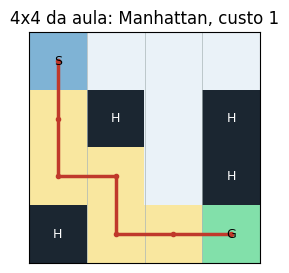

In [3]:
ax = desenhar(MAPA_AULA, r, titulo="4x4 da aula: Manhattan, custo 1")
plt.savefig(FIGURAS / "mapa_aula.png", dpi=150, bbox_inches="tight")
plt.show()

Em amarelo estão as células expandidas e em vermelho o caminho.

### Execução no Gymnasium

As ações do A* são executadas no `FrozenLake-v1` com `is_slippery=False`. O episódio precisa terminar no `G` com recompensa 1.

In [4]:
recompensa, terminou, estados = executar_no_ambiente(MAPA_AULA, r.acoes)
print(f"recompensa = {recompensa}, terminou = {terminou}, estados = {estados}")
assert terminou and recompensa == 1.0

recompensa = 1.0, terminou = True, estados = [0, 4, 8, 9, 13, 14, 15]


### Comparação com o notebook base da aula

O ponto de partida é o notebook do professor, [`Pratica_2_Completa.ipynb`](./Pratica_2_Completa.ipynb), que estava no Drive (slide 36). Ele roda o A* com Manhattan e custo 1 num mapa 8x8 próprio, com S em (0,7) e G em (7,7), e gera um GIF do agente andando. O `astar.py` mantém a mesma ideia e muda o seguinte:

| Notebook base | `astar.py` | Por quê |
|---|---|---|
| A heap guarda o caminho inteiro em cada entrada | Cada nó guarda `pai`, `acao` e `g` (slide 35), e o caminho é reconstruído no fim | Segue a estrutura de nó pedida e evita copiar listas a cada sucessor |
| `cost_function(acc_cost, a, b)` devolve o custo acumulado, e `custo_mov` é global | `custo_fn(origem, destino)` devolve só o custo do passo e é passada como parâmetro, como `heuristica_fn` | Os experimentos trocam o custo e a heurística sem editar a busca |
| O nó fechado nunca é reaberto, e todo vizinho é empilhado | Guarda o melhor g por célula, só empilha se o g melhorar e reabre um fechado se achar g menor | Com heurísticas que superestimam o custo, o caminho devolvido continua sendo o melhor encontrado |
| Empate em f desfeito pelo menor g | Empate desfeito pelo menor h e depois pela ordem de inserção | Tende a expandir menos nós, e a ordem fica determinística |
| Devolve só o caminho (ou `None`) | Devolve caminho, ações, custo, nós expandidos e gerados, tamanho máximo da fronteira, tempo e lista de fechados | Métricas necessárias para os experimentos e o relatório |
| GIF com `imageio` | `gerar_gif` com Pillow (já instalado junto com o matplotlib) | Uma dependência a menos |

No mapa do notebook base, as duas implementações encontram exatamente o mesmo caminho, com 25 passos.

In [5]:
MAPA_BASE = ["FFFFFFFS",
             "FHFHHHHH",
             "FHFFHFFF",
             "FHHFFFHF",
             "FHFHHHFF",
             "FHFFFHFH",
             "FHFHFHHH",
             "FFFHFFFG"]

CAMINHO_DO_NOTEBOOK_BASE = [(0, 7), (0, 6), (0, 5), (0, 4), (0, 3), (0, 2), (0, 1), (0, 0), (1, 0),
                            (2, 0), (3, 0), (4, 0), (5, 0), (6, 0), (7, 0), (7, 1), (7, 2), (6, 2),
                            (5, 2), (5, 3), (5, 4), (6, 4), (7, 4), (7, 5), (7, 6), (7, 7)]

r_base = a_star(MAPA_BASE)
validar_caminho(MAPA_BASE, r_base)
assert r_base.caminho == CAMINHO_DO_NOTEBOOK_BASE

print(grid_com_caminho(MAPA_BASE, r_base))
pd.DataFrame([r_base.metricas()])

*******S
*HFHHHHH
*HFFHFFF
*HHFFFHF
*HFHHHFF
*H***HFH
*H*H*HHH
***H***G


,encontrou,custo,passos,expandidos,gerados,max_fronteira,tempo_ms
0,True,25.0,25,38,40,2,0.228


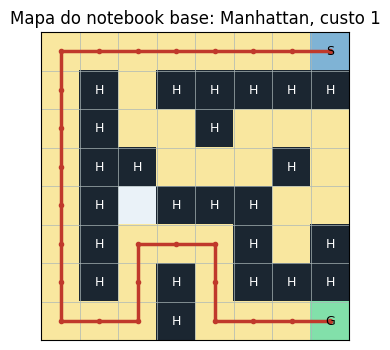

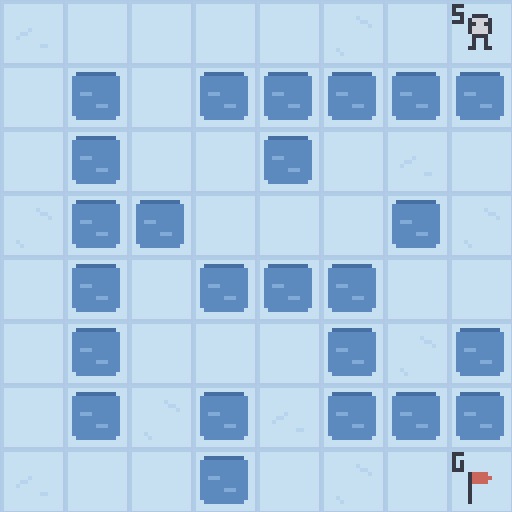

In [6]:
fig, ax = plt.subplots(figsize=(4, 4))
desenhar(MAPA_BASE, r_base, ax=ax, titulo="Mapa do notebook base: Manhattan, custo 1")
plt.savefig(FIGURAS / "mapa_base.png", dpi=150, bbox_inches="tight")
plt.show()

gerar_gif(MAPA_BASE, r_base.acoes, FIGURAS / "mapa_base.gif")
display(Image(filename=FIGURAS / "mapa_base.gif"))

Nesse mapa a Manhattan engana: o G fica logo abaixo do S, mas a fileira de buracos obriga o agente a dar a volta pela esquerda. Por isso o A* expande 38 nós para um caminho de 25 passos. Esse é um bom exemplo de mapa que engana a heurística.

### Verificação em mapas aleatórios

Para conferir a implementação fora do exemplo da aula, a busca roda em mapas aleatórios do Gymnasium (`p = 0.8`, 10 sementes por tamanho) com três heurísticas. Com uma heurística admissível, o custo precisa ser igual ao de $h = 0$ (Dijkstra), e o número de nós expandidos não pode ser maior.

Esta tabela só valida a implementação. A análise de tamanho de grid e de heurísticas fica nos experimentos de cenário.

In [7]:
linhas = []
for tamanho in (4, 8, 16, 32):
    for semente in range(10):
        mapa = generate_random_map(size=tamanho, p=0.8, seed=SEMENTE + semente)
        base = a_star(mapa, heuristica_fn=heuristica_nula)
        for nome, h in [("nula (Dijkstra)", heuristica_nula), ("manhattan", manhattan), ("euclidiana", euclidiana)]:
            res = a_star(mapa, heuristica_fn=h)
            validar_caminho(mapa, res)
            assert math.isclose(res.custo, base.custo)
            linhas.append({"tamanho": tamanho, "semente": semente, "heuristica": nome, **res.metricas()})
        rec, fim, _ = executar_no_ambiente(mapa, base.acoes)
        assert fim and rec == 1.0

df = pd.DataFrame(linhas)
df.groupby(["tamanho", "heuristica"])[["custo", "expandidos", "max_fronteira", "tempo_ms"]].mean().round(2)

custo  expandidos  max_fronteira  tempo_ms
tamanho heuristica                                                 
4       euclidiana         6.0         8.4            4.0      0.03
        manhattan          6.0         6.4            3.7      0.02
        nula (Dijkstra)    6.0        11.9            3.4      0.03
8       euclidiana        14.0        34.8           10.1      0.12
        manhattan         14.0        17.7           12.3      0.06
        nula (Dijkstra)   14.0        48.6            7.7      0.13
16      euclidiana        30.0       167.0           26.6      0.59
        manhattan         30.0        44.4           30.6      0.19
        nula (Dijkstra)   30.0       206.6           16.1      0.67
32      euclidiana        62.0       706.9           52.7      2.28
        manhattan         62.0       122.3           86.9      0.47
        nula (Dijkstra)   62.0       817.3           33.6      2.51

Os 40 mapas passam nas três verificações (caminho válido, custo igual ao de Dijkstra e recompensa 1 no Gymnasium), então a implementação está pronta para os experimentos.

---

## Experimentos de cenário

Na aula, o A* foi usado só no 4x4 padrão. Aqui o custo continua sendo **1 por passo**, e o que muda é o mapa:

1. **tamanho do grid**, de 4x4 a 64x64;
2. **posições do início e do objetivo** num mesmo mapa;
3. **buracos**: densidade aleatória e padrões montados à mão (parede, armadilha em "U", labirinto);
4. **mapas sem solução**;
5. **heurísticas**: além da Manhattan, $h = 0$ (Dijkstra), Euclidiana e Manhattan com peso $w > 1$, que deixa de ser admissível.

Os mapas são gerados pelo módulo [`cenarios.py`](./cenarios.py). Em todas as execuções, `rodar` valida o caminho, confere o custo contra Dijkstra e, quando a busca vai de S a G, executa as ações no `FrozenLake-v1` (o episódio precisa terminar no G com recompensa 1).

Métricas: **custo** do caminho, **nós expandidos** (retirados da fronteira), **tamanho máximo da fronteira** (memória) e tempo em ms. O tempo varia de uma execução para outra, então a comparação principal é pelo número de nós expandidos.

In [8]:
from astar import encontrar
from cenarios import (alcancaveis, existe_caminho, manhattan_ponderada, mapa_armadilha_u,
                      mapa_labirinto, mapa_objetivo_isolado, mapa_parede, montar_mapa,
                      posicionar, rodar)

HEURISTICAS = {
    "nula (Dijkstra)": heuristica_nula,
    "manhattan": manhattan,
    "euclidiana": euclidiana,
}
HEURISTICAS_PONDERADAS = {
    "manhattan ×1.5": manhattan_ponderada(1.5),
    "manhattan ×2": manhattan_ponderada(2),
    "manhattan ×5": manhattan_ponderada(5),
}

# Cor fixa por heurística, a mesma em todos os gráficos.
CORES = {
    "nula (Dijkstra)": "#2a78d6",
    "manhattan": "#eb6834",
    "euclidiana": "#1baf7a",
    "manhattan ×1.5": "#eda100",
    "manhattan ×2": "#e87ba4",
    "manhattan ×5": "#6250d6",
}

def estilo(ax, titulo, xlabel, ylabel):
    ax.set_title(titulo, loc="left", fontsize=11)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#8a8984")
    ax.tick_params(colors="#52514e")
    ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
    ax.set_axisbelow(True)

def linhas_por_heuristica(ax, df, x, y, heuristicas):
    for nome in heuristicas:
        d = df[df.heuristica == nome]
        ax.plot(d[x], d[y], color=CORES[nome], linewidth=2, marker="o", markersize=6, label=nome)

### 1. Tamanho do grid

Para cada tamanho são usados 20 mapas do `generate_random_map` do Gymnasium, com `p = 0.8` (80% de gelo), S em (0,0) e G no canto oposto. O gerador do Gymnasium só devolve mapas que têm caminho.

In [9]:
TAMANHOS = [4, 8, 16, 32, 64]
N_MAPAS = 20

linhas = []
for tamanho in TAMANHOS:
    for k in range(N_MAPAS):
        mapa = generate_random_map(size=tamanho, p=0.8, seed=SEMENTE + k)
        livres = sum(l.count("F") for l in mapa) + 2
        for linha in rodar(mapa, HEURISTICAS):
            linhas.append({"tamanho": tamanho, "mapa": k, "livres": livres, **linha})

df_tam = pd.DataFrame(linhas)
df_tam["% livres expandidas"] = 100 * df_tam.expandidos / df_tam.livres
resumo_tam = (df_tam.groupby(["tamanho", "heuristica"], sort=False)
              [["custo", "expandidos", "% livres expandidas", "max_fronteira", "tempo_ms"]]
              .mean().round(1))
resumo_tam

custo  expandidos  % livres expandidas  \
tamanho heuristica                                                
4       nula (Dijkstra)    6.0        11.8                 90.3   
        manhattan          6.0         6.6                 51.2   
        euclidiana         6.0         8.2                 62.5   
8       nula (Dijkstra)   14.0        49.3                 94.6   
        manhattan         14.0        17.0                 32.7   
        euclidiana        14.0        35.2                 67.4   
16      nula (Dijkstra)   30.0       206.5                 98.9   
        manhattan         30.0        43.6                 20.9   
        euclidiana        30.0       165.2                 79.1   
32      nula (Dijkstra)   62.2       813.2                 99.3   
        manhattan         62.2       123.2                 15.0   
        euclidiana        62.2       695.6                 84.9   
64      nula (Dijkstra)  126.0      3265.4                 99.7   
        manhattan        126.0       366.2                 11.2   
        euclidiana       126.0      2939.3                 89.7   

                         max_fronteira  tempo_ms  
tamanho heuristica                                
4       nula (Dijkstra)            3.2       0.0  
        manhattan                  3.8       0.0  
        euclidiana                 4.0       0.0  
8       nula (Dijkstra)            7.7       0.1  
        manhattan                 12.0       0.1  
        euclidiana                10.2       0.1  
16      nula (Dijkstra)           16.2       0.6  
        manhattan                 32.2       0.2  
        euclidiana                25.6       0.5  
32      nula (Dijkstra)           33.0       2.5  
        manhattan                 85.8       0.6  
        euclidiana                51.4       2.5  
64      nula (Dijkstra)           63.8       9.5  
        manhattan                239.1       1.4  
        euclidiana               106.0       9.4

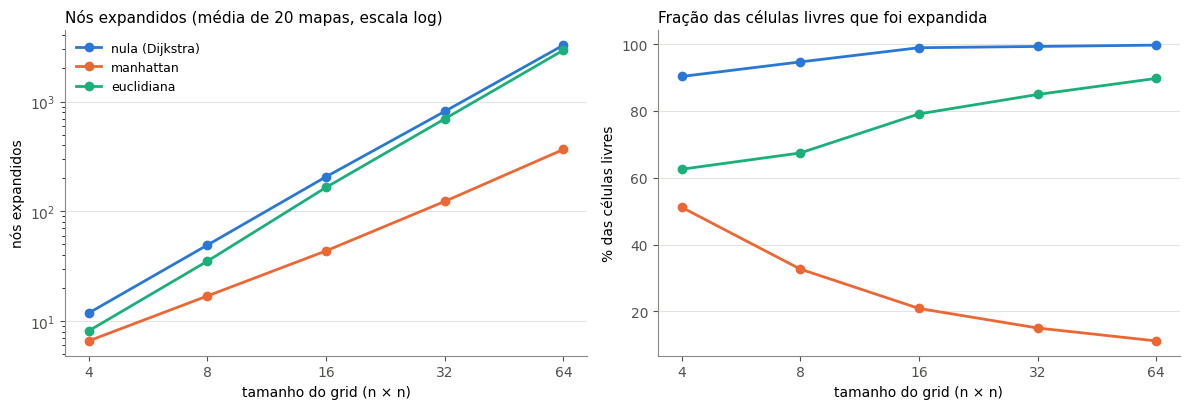

In [10]:
media_tam = df_tam.groupby(["heuristica", "tamanho"], sort=False).mean(numeric_only=True).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
linhas_por_heuristica(axes[0], media_tam, "tamanho", "expandidos", HEURISTICAS)
axes[0].set_yscale("log")
estilo(axes[0], "Nós expandidos (média de 20 mapas, escala log)", "tamanho do grid (n × n)", "nós expandidos")
linhas_por_heuristica(axes[1], media_tam, "tamanho", "% livres expandidas", HEURISTICAS)
estilo(axes[1], "Fração das células livres que foi expandida", "tamanho do grid (n × n)", "% das células livres")
for ax in axes:
    ax.set_xscale("log", base=2)
    ax.set_xticks(TAMANHOS, [str(t) for t in TAMANHOS])
axes[0].legend(frameon=False, fontsize=9, loc="upper left")
plt.tight_layout()
plt.savefig(FIGURAS / "cenario_tamanho.png", dpi=150, bbox_inches="tight")
plt.show()

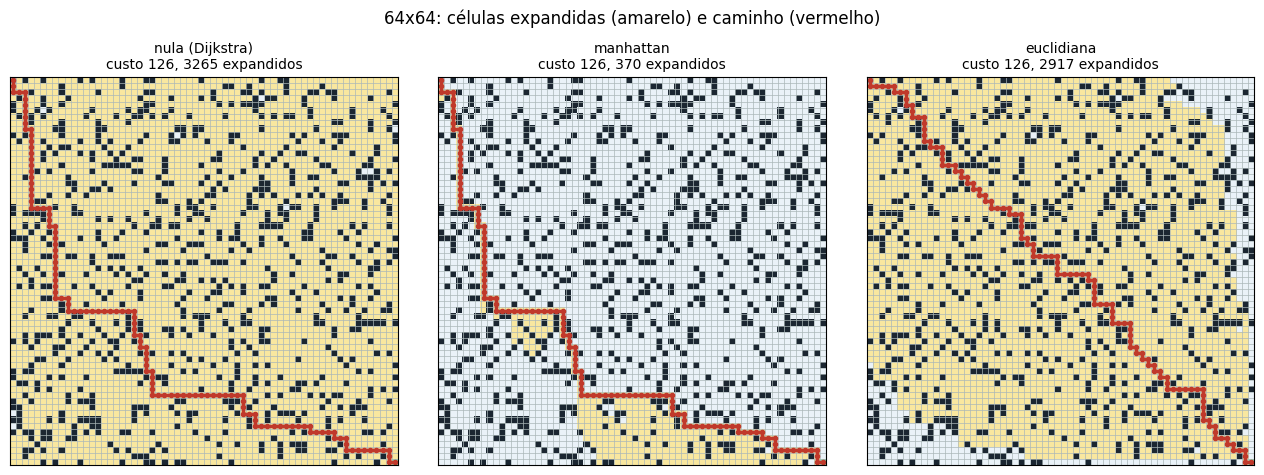

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.8))
mapa64 = generate_random_map(size=64, p=0.8, seed=SEMENTE)
for ax, (nome, h) in zip(axes, HEURISTICAS.items()):
    desenhar(mapa64, a_star(mapa64, heuristica_fn=h), ax=ax)
    ax.set_title(f"{nome}\n{ax.get_title()}", fontsize=10)
plt.suptitle("64x64: células expandidas (amarelo) e caminho (vermelho)")
plt.tight_layout(rect=(0, 0, 1, 0.94))
plt.savefig(FIGURAS / "cenario_64x64.png", dpi=150, bbox_inches="tight")
plt.show()

### 2. Posições do início e do objetivo

O mesmo mapa 16x16 (mesmos buracos) é usado com S e G em lugares diferentes. A semente do mapa é escolhida para que todas as combinações tenham caminho.

A coluna `h(S) / custo` mede o quanto a Manhattan inicial acerta o custo real: 1 quer dizer que o caminho é tão curto quanto a distância em grade, sem desvios.

In [12]:
N = 16
POSICOES = {
    "cantos opostos":         ((0, 0), (15, 15)),
    "mesmo lado":             ((0, 0), (0, 15)),
    "centro → canto":         ((8, 8), (15, 15)),
    "canto → centro":         ((15, 15), (8, 8)),
    "vizinhos na diagonal":   ((7, 7), (8, 8)),
    "objetivo entre buracos": None,  # escolhido abaixo
}

def mais_cercada(mapa, inicio):
    # Célula alcançável com mais buracos em volta (desempate: a mais distante do início).
    candidatas = []
    for i in range(len(mapa)):
        for j in range(len(mapa)):
            if mapa[i][j] == "H" or (i, j) == inicio:
                continue
            buracos = sum(1 for di, dj in ((0, 1), (1, 0), (0, -1), (-1, 0))
                          if 0 <= i + di < len(mapa) and 0 <= j + dj < len(mapa)
                          and mapa[i + di][j + dj] == "H")
            candidatas.append((buracos, manhattan((i, j), inicio), (i, j)))
    for _, _, celula in sorted(candidatas, reverse=True):
        if existe_caminho(posicionar(mapa, inicio, celula)):
            return celula

for semente in range(SEMENTE, SEMENTE + 100):
    base16 = montar_mapa(N, p_livre=0.8, semente=semente)
    POSICOES["objetivo entre buracos"] = ((0, 0), mais_cercada(base16, (0, 0)))
    if all(existe_caminho(posicionar(base16, s, g)) for s, g in POSICOES.values()):
        break
print("semente do mapa:", semente)

linhas = []
for nome, (s, g) in POSICOES.items():
    mapa = posicionar(base16, s, g)
    for linha in rodar(mapa, {"nula (Dijkstra)": heuristica_nula, "manhattan": manhattan}):
        linhas.append({"posições": nome, "S": s, "G": g, "h(S)": manhattan(s, g), **linha})

df_pos = pd.DataFrame(linhas)
tab_pos = df_pos.pivot_table(index=["posições", "S", "G", "h(S)", "custo"], columns="heuristica",
                             values="expandidos", sort=False).reset_index()
tab_pos["h(S) / custo"] = (tab_pos["h(S)"] / tab_pos["custo"]).round(2)
tab_pos["economia da manhattan (%)"] = (100 * (1 - tab_pos["manhattan"] / tab_pos["nula (Dijkstra)"])).round(1)
tab_pos.columns.name = None
tab_pos

semente do mapa: 42


,posições,S,G,h(S),custo,nula (Dijkstra),manhattan,h(S) / custo,economia da manhattan (%)
0,cantos opostos,"(0, 0)","(15, 15)",30.0,30.0,202.0,45.0,1.00,77.7
1,mesmo lado,"(0, 0)","(0, 15)",15.0,17.0,96.0,17.0,0.88,82.3
2,centro → canto,"(8, 8)","(15, 15)",14.0,14.0,193.0,23.0,1.00,88.1
3,canto → centro,"(15, 15)","(8, 8)",14.0,14.0,67.0,14.0,1.00,79.1
4,vizinhos na diagonal,"(7, 7)","(8, 8)",2.0,2.0,9.0,2.0,1.00,77.8
5,objetivo entre buracos,"(0, 0)","(2, 5)",7.0,7.0,25.0,12.0,1.00,52.0


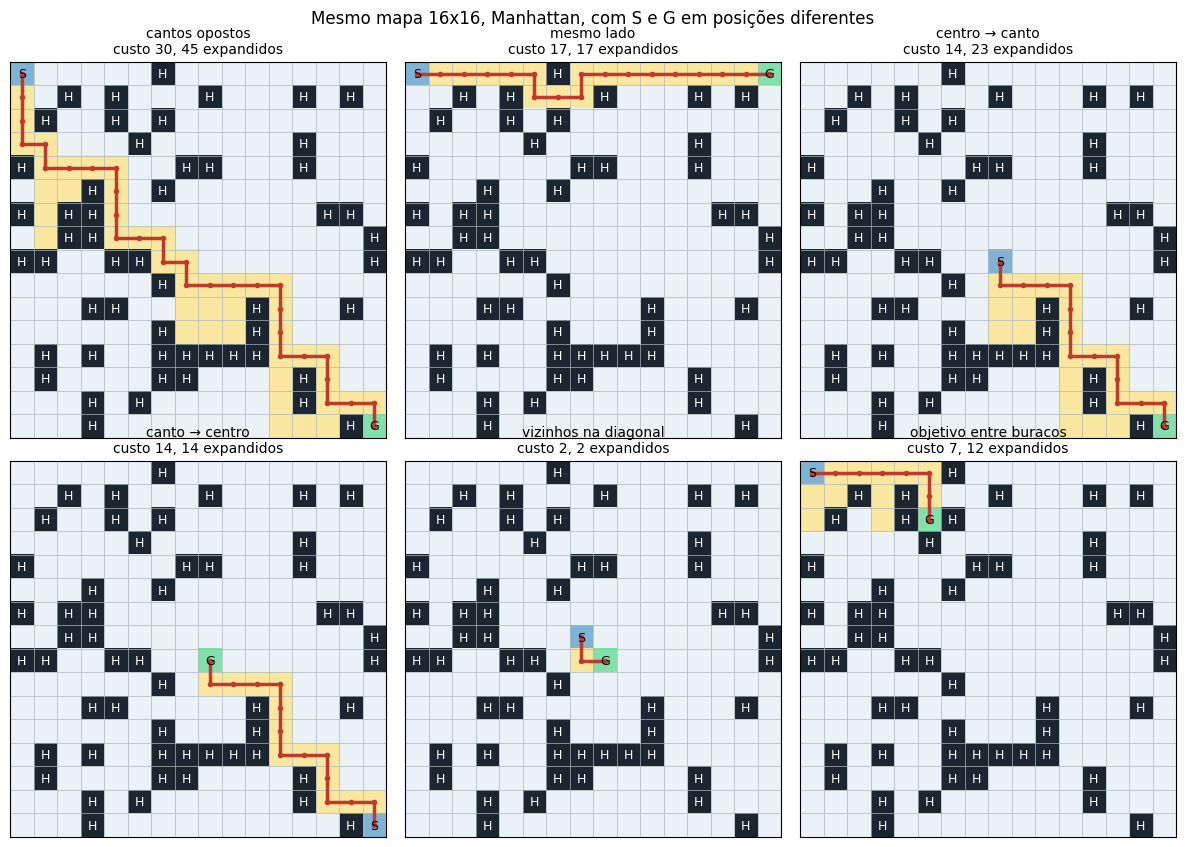

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8.6))
for ax, (nome, (s, g)) in zip(axes.flat, POSICOES.items()):
    mapa = posicionar(base16, s, g)
    desenhar(mapa, a_star(mapa, heuristica_fn=manhattan), ax=ax)
    ax.set_title(f"{nome}\n{ax.get_title()}", fontsize=10)
plt.suptitle("Mesmo mapa 16x16, Manhattan, com S e G em posições diferentes")
plt.tight_layout()
plt.savefig(FIGURAS / "cenario_posicoes.png", dpi=150, bbox_inches="tight")
plt.show()

### 3. Buracos

#### 3a. Densidade

Mapas 32x32 com S em (0,0) e G em (31,31), em que cada célula vira buraco com probabilidade $1 - p$. Aqui os mapas **não** são filtrados, então nem todos têm caminho. São 50 mapas por valor de $p$. A coluna `custo / h(S)` compara o caminho real com a Manhattan inicial, que é 62.

In [14]:
P_LIVRE = [1.0, 0.9, 0.8, 0.7, 0.65, 0.6]
N_MAPAS_DENS = 50

linhas = []
for p in P_LIVRE:
    for k in range(N_MAPAS_DENS):
        mapa = montar_mapa(32, p_livre=p, semente=SEMENTE * 1000 + k)
        for linha in rodar(mapa, {"nula (Dijkstra)": heuristica_nula, "manhattan": manhattan}):
            linhas.append({"p": p, "mapa": k, **linha})

df_dens = pd.DataFrame(linhas)
com_caminho = df_dens[df_dens.encontrou]
so_manh = com_caminho[com_caminho.heuristica == "manhattan"].groupby("p")
so_nula = com_caminho[com_caminho.heuristica == "nula (Dijkstra)"].groupby("p")
tab_dens = pd.DataFrame({
    "% com caminho": df_dens[df_dens.heuristica == "manhattan"].groupby("p").encontrou.mean() * 100,
    "custo médio": so_manh.custo.mean(),
    "custo / h(S)": so_manh.custo.mean() / 62,
    "expandidos nula": so_nula.expandidos.mean(),
    "expandidos manhattan": so_manh.expandidos.mean(),
}).sort_index(ascending=False).round(2)
tab_dens["economia da manhattan (%)"] = (100 * (1 - tab_dens["expandidos manhattan"] / tab_dens["expandidos nula"])).round(1)
tab_dens

,% com caminho,custo médio,custo / h(S),expandidos nula,expandidos manhattan,economia da manhattan (%)
p,,,,,,
1.00,100.0,62.00,1.00,1023.00,62.00,93.9
0.90,100.0,62.00,1.00,919.24,103.06,88.8
0.80,86.0,62.05,1.00,814.42,131.67,83.8
0.70,40.0,63.10,1.02,691.70,181.20,73.8
0.65,26.0,66.31,1.07,587.38,234.77,60.0
0.60,8.0,80.00,1.29,412.25,267.50,35.1


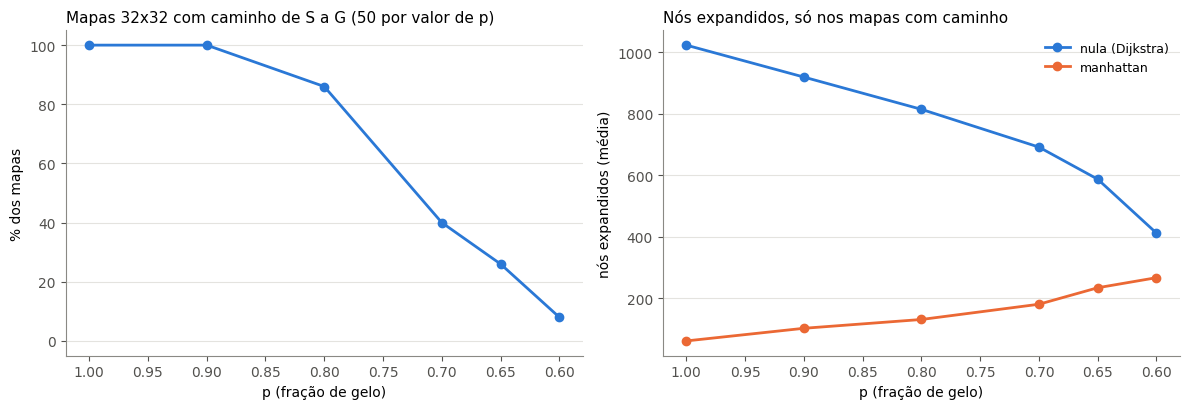

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ps = tab_dens.index.to_numpy()
axes[0].plot(ps, tab_dens["% com caminho"], color="#2a78d6", linewidth=2, marker="o", markersize=6)
estilo(axes[0], "Mapas 32x32 com caminho de S a G (50 por valor de p)", "p (fração de gelo)", "% dos mapas")
axes[0].set_ylim(-5, 105)
d = com_caminho.groupby(["heuristica", "p"], sort=False).expandidos.mean().reset_index().sort_values("p")
linhas_por_heuristica(axes[1], d, "p", "expandidos", ["nula (Dijkstra)", "manhattan"])
estilo(axes[1], "Nós expandidos, só nos mapas com caminho", "p (fração de gelo)", "nós expandidos (média)")
axes[1].legend(frameon=False, fontsize=9)
for ax in axes:
    ax.invert_xaxis()
plt.tight_layout()
plt.savefig(FIGURAS / "cenario_densidade.png", dpi=150, bbox_inches="tight")
plt.show()

#### 3b. Padrões montados à mão

Mapas aleatórios escondem casos em que a heurística é enganada. Os padrões abaixo isolam esses casos:

- **parede com passagem alinhada**: a passagem fica na linha de S e G, então a Manhattan é exata;
- **parede com passagem na ponta**: a passagem fica no canto, e o caminho real é quase o dobro da estimativa;
- **armadilha em "U"**: um U aberto para o S fica entre S e G, e a Manhattan puxa a busca para dentro dele;
- **labirinto perfeito** (31x31): só existe um caminho, cheio de voltas;
- **labirinto com ciclos**: o mesmo labirinto com 10% das paredes internas removidas.

In [16]:
PADROES = {
    "parede, passagem alinhada": mapa_parede(16, 8),
    "parede, passagem na ponta": mapa_parede(16, 0),
    "armadilha em U": mapa_armadilha_u(16),
    "labirinto perfeito": mapa_labirinto(31, semente=SEMENTE),
    "labirinto com ciclos": mapa_labirinto(31, semente=SEMENTE, abrir=0.10),
}

linhas = []
for nome, mapa in PADROES.items():
    s, g = encontrar(mapa, "S"), encontrar(mapa, "G")
    for linha in rodar(mapa, HEURISTICAS):
        linhas.append({"padrão": nome, "h(S)": manhattan(s, g), "alcançáveis": alcancaveis(mapa), **linha})

df_pad = pd.DataFrame(linhas)
tab_pad = df_pad.pivot_table(index=["padrão", "h(S)", "custo", "alcançáveis"], columns="heuristica",
                             values="expandidos", sort=False).reset_index()
tab_pad.columns.name = None
tab_pad

,padrão,h(S),custo,alcançáveis,nula (Dijkstra),manhattan,euclidiana
0,"parede, passagem alinhada",15.0,15.0,241,170.0,15.0,15.0
1,"parede, passagem na ponta",15.0,31.0,241,212.0,136.0,178.0
2,armadilha em U,14.0,24.0,231,230.0,107.0,181.0
3,labirinto perfeito,60.0,264.0,511,346.0,315.0,316.0
4,labirinto com ciclos,60.0,84.0,533,514.0,341.0,434.0


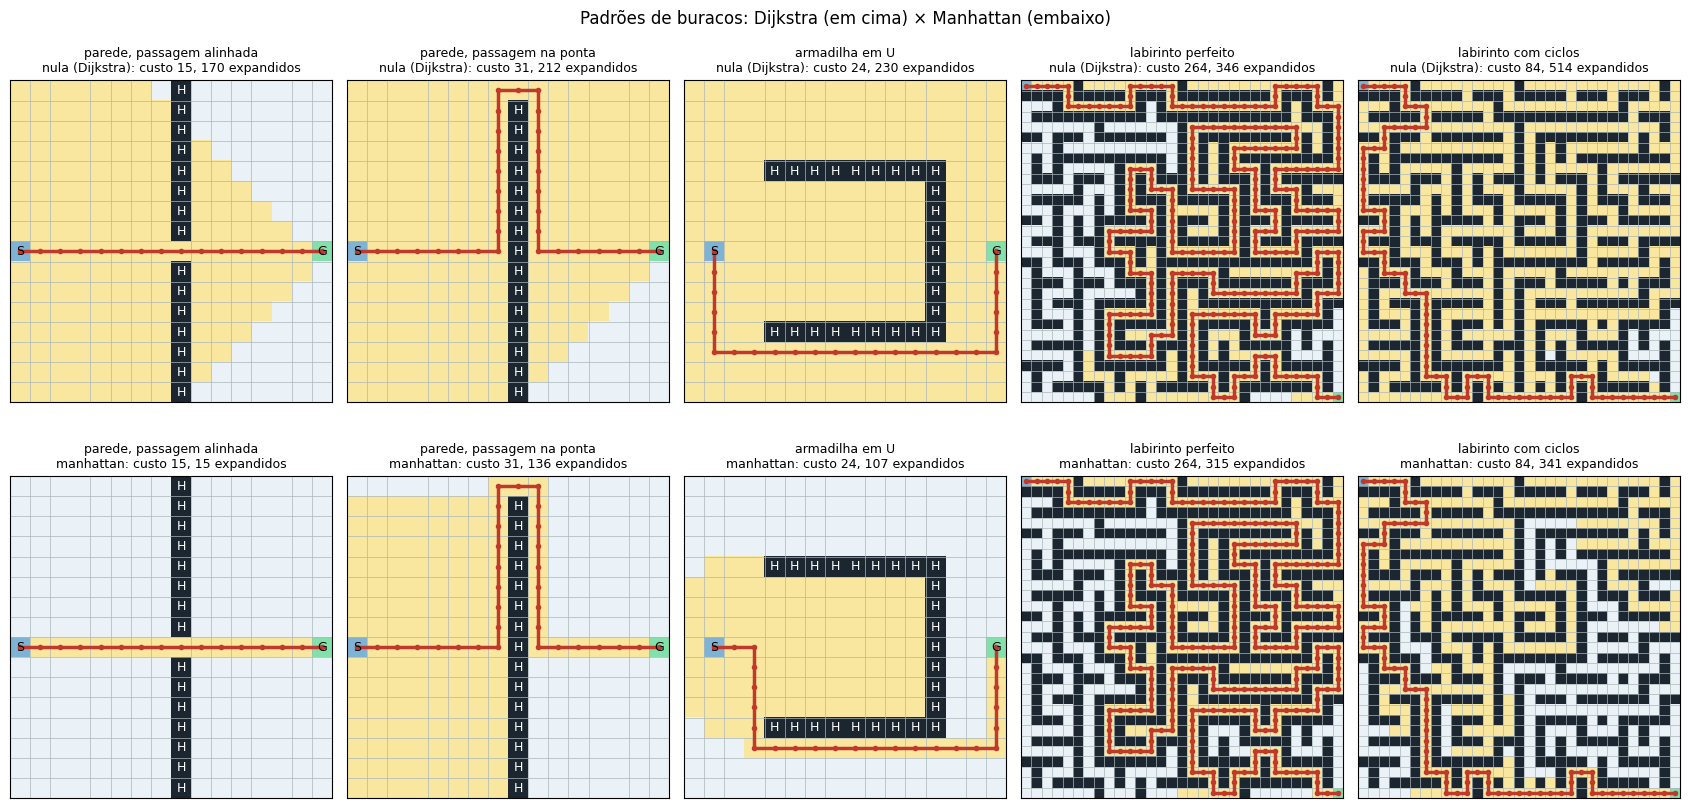

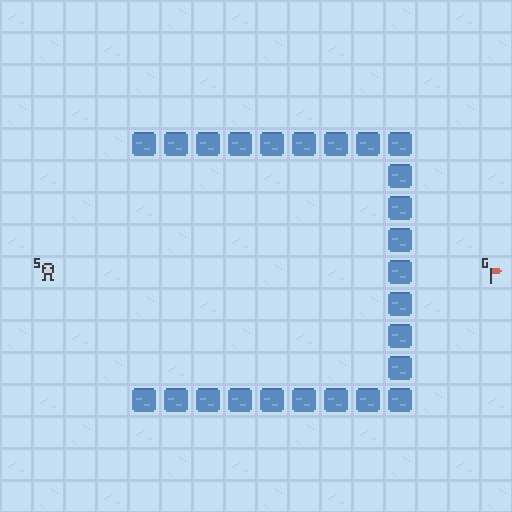

In [17]:
fig, axes = plt.subplots(2, len(PADROES), figsize=(17, 8.6))
for col, (nome, mapa) in enumerate(PADROES.items()):
    for lin, (nome_h, h) in enumerate([("nula (Dijkstra)", heuristica_nula), ("manhattan", manhattan)]):
        ax = axes[lin, col]
        desenhar(mapa, a_star(mapa, heuristica_fn=h), ax=ax)
        ax.set_title(f"{nome}\n{nome_h}: {ax.get_title()}", fontsize=9)
plt.suptitle("Padrões de buracos: Dijkstra (em cima) × Manhattan (embaixo)")
plt.tight_layout(h_pad=2.5)
plt.savefig(FIGURAS / "cenario_padroes.png", dpi=150, bbox_inches="tight")
plt.show()

gerar_gif(PADROES["armadilha em U"], a_star(PADROES["armadilha em U"]).acoes,
          FIGURAS / "cenario_armadilha_u.gif", duracao_ms=200)
display(Image(filename=FIGURAS / "cenario_armadilha_u.gif"))

### 4. Mapas sem solução

Quando não há caminho, o A* só para depois de esvaziar a fronteira. Os casos testados são o G cercado por um anel de buracos (16x16) e três dos mapas de densidade $p = 0.6$ que ficaram sem caminho.

In [18]:
casos = {"objetivo cercado (16x16)": mapa_objetivo_isolado(16)}
sem_caminho_06 = [k for k in range(N_MAPAS_DENS)
                  if not existe_caminho(montar_mapa(32, p_livre=0.6, semente=SEMENTE * 1000 + k))]
for k in sem_caminho_06[:3]:
    casos[f"p = 0.6, mapa {k} (32x32)"] = montar_mapa(32, p_livre=0.6, semente=SEMENTE * 1000 + k)

linhas = []
for nome, mapa in casos.items():
    for linha in rodar(mapa, {**HEURISTICAS, "manhattan ×2": HEURISTICAS_PONDERADAS["manhattan ×2"]}):
        linhas.append({"mapa": nome, "alcançáveis a partir de S": alcancaveis(mapa), **linha})

df_sem = pd.DataFrame(linhas)
tab_sem = df_sem.pivot_table(index=["mapa", "alcançáveis a partir de S"], columns="heuristica",
                             values="expandidos", sort=False).reset_index()
tab_sem.columns.name = None
tab_sem

,mapa,alcançáveis a partir de S,nula (Dijkstra),manhattan,euclidiana,manhattan ×2
0,objetivo cercado (16x16),247,247.0,247.0,247.0,623.0
1,"p = 0.6, mapa 0 (32x32)",29,29.0,29.0,29.0,29.0
2,"p = 0.6, mapa 1 (32x32)",8,8.0,8.0,8.0,8.0
3,"p = 0.6, mapa 2 (32x32)",493,493.0,493.0,493.0,598.0


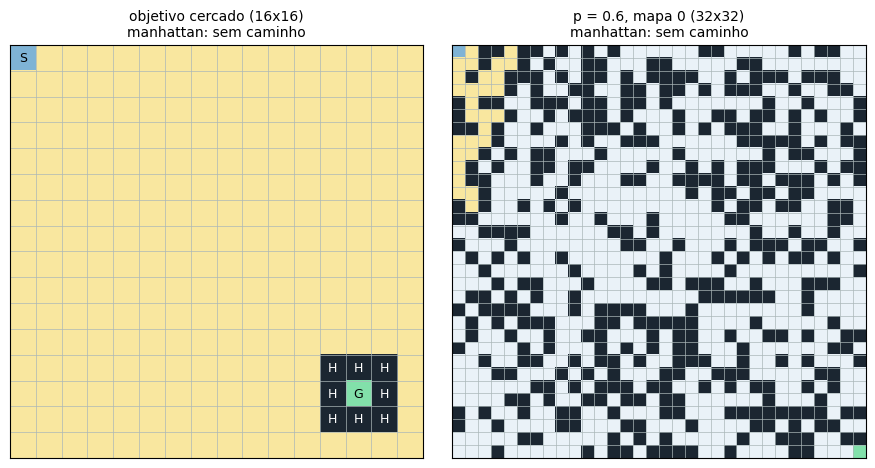

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4.6))
for ax, (nome, mapa) in zip(axes, list(casos.items())[:2]):
    desenhar(mapa, a_star(mapa, heuristica_fn=manhattan), ax=ax)
    ax.set_title(f"{nome}\nmanhattan: {ax.get_title()}", fontsize=10)
plt.tight_layout()
plt.savefig(FIGURAS / "cenario_sem_caminho.png", dpi=150, bbox_inches="tight")
plt.show()

### 5. Heurísticas

As heurísticas são comparadas em 50 mapas 32x32 do `generate_random_map` para cada densidade ($p = 0.8$ e $p = 0.7$) e nos padrões da seção 3b. A Manhattan com peso $w$ multiplica a estimativa por $w$. Para $w > 1$ ela pode superestimar o custo real, então deixa de ser admissível, e o A* perde a garantia de achar o caminho de menor custo. A coluna `% subótimos` conta em quantos mapas o custo ficou acima do de Dijkstra, e `excesso máx. (%)` mostra o pior caso.

In [20]:
TODAS = {**HEURISTICAS, **HEURISTICAS_PONDERADAS}

linhas = []
for p in (0.8, 0.7):
    for k in range(50):
        mapa = generate_random_map(size=32, p=p, seed=SEMENTE + k)
        for linha in rodar(mapa, TODAS):
            linhas.append({"conjunto": f"aleatórios p = {p}", "mapa": k, **linha})
for nome, mapa in PADROES.items():
    for linha in rodar(mapa, TODAS):
        linhas.append({"conjunto": "padrões (3b)", "mapa": nome, **linha})

df_h = pd.DataFrame(linhas)
df_h["subotimo"] = df_h["excesso_%"] > 1e-9
tab_h = (df_h.groupby(["conjunto", "heuristica"], sort=False)
         .agg(expandidos=("expandidos", "mean"), max_fronteira=("max_fronteira", "mean"),
              **{"% subótimos": ("subotimo", lambda s: 100 * s.mean()),
                 "excesso médio (%)": ("excesso_%", "mean"),
                 "excesso máx. (%)": ("excesso_%", "max")})
         .round(1))
tab_h

expandidos  max_fronteira  % subótimos  \
conjunto           heuristica                                                
aleatórios p = 0.8 nula (Dijkstra)       814.8           32.4          0.0   
                   manhattan             133.4           90.4          0.0   
                   euclidiana            695.3           52.4          0.0   
                   manhattan ×1.5        102.2           66.5         90.0   
                   manhattan ×2           97.7           64.4         98.0   
                   manhattan ×5           93.5           63.9        100.0   
aleatórios p = 0.7 nula (Dijkstra)       683.3           27.5          0.0   
                   manhattan             192.0           75.7          0.0   
                   euclidiana            500.3           42.4          0.0   
                   manhattan ×1.5        122.0           56.8         74.0   
                   manhattan ×2          113.0           55.4         88.0   
                   manhattan ×5          113.2           55.6         98.0   
padrões (3b)       nula (Dijkstra)       294.4           12.6          0.0   
                   manhattan             182.8           20.8          0.0   
                   euclidiana            224.8           20.6          0.0   
                   manhattan ×1.5        177.2           22.0          0.0   
                   manhattan ×2          177.0           22.2         20.0   
                   manhattan ×5          157.2           22.6         20.0   

                                    excesso médio (%)  excesso máx. (%)  
conjunto           heuristica                                            
aleatórios p = 0.8 nula (Dijkstra)                0.0               0.0  
                   manhattan                      0.0               0.0  
                   euclidiana                     0.0               0.0  
                   manhattan ×1.5                 5.6              12.9  
                   manhattan ×2                   9.5              19.4  
                   manhattan ×5                  15.1              38.7  
aleatórios p = 0.7 nula (Dijkstra)                0.0               0.0  
                   manhattan                      0.0               0.0  
                   euclidiana                     0.0               0.0  
                   manhattan ×1.5                 4.2              16.1  
                   manhattan ×2                   8.3              28.1  
                   manhattan ×5                  15.2              53.1  
padrões (3b)       nula (Dijkstra)                0.0               0.0  
                   manhattan                      0.0               0.0  
                   euclidiana                     0.0               0.0  
                   manhattan ×1.5                 0.0               0.0  
                   manhattan ×2                   2.9              14.3  
                   manhattan ×5                   5.7              28.6

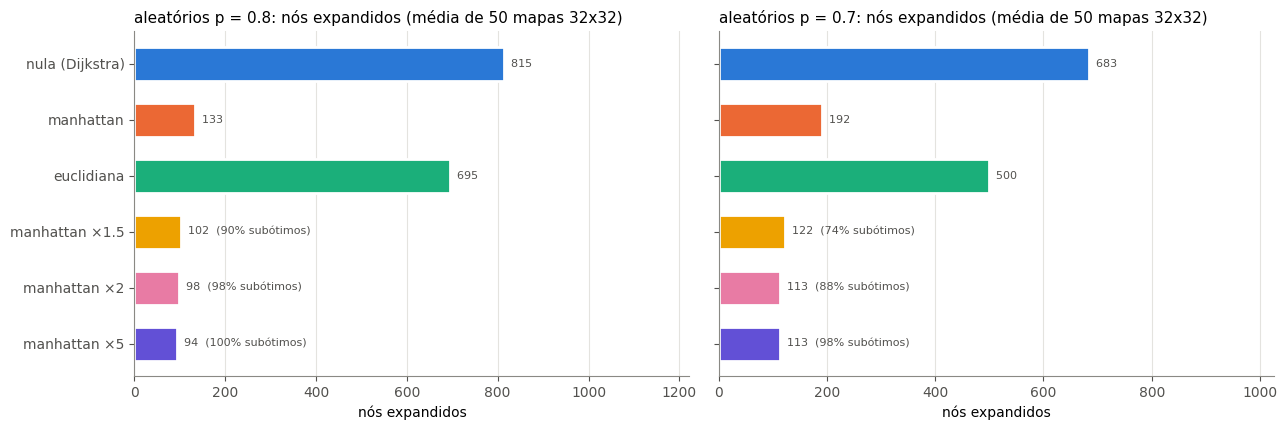

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for ax, conjunto in zip(axes, ["aleatórios p = 0.8", "aleatórios p = 0.7"]):
    d = tab_h.loc[conjunto].reset_index()
    y = list(range(len(d)))
    ax.barh(y, d.expandidos, color=[CORES[n] for n in d.heuristica], height=0.6,
            edgecolor="white", linewidth=2)
    for yi, (v, sub) in enumerate(zip(d.expandidos, d["% subótimos"])):
        rotulo = f"{v:.0f}" + (f"  ({sub:.0f}% subótimos)" if sub > 0 else "")
        ax.text(v, yi, "  " + rotulo, va="center", fontsize=8, color="#52514e")
    ax.set_yticks(y, d.heuristica)
    estilo(ax, f"{conjunto}: nós expandidos (média de 50 mapas 32x32)", "nós expandidos", "")
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", color="#e4e3df", linewidth=0.8)
    ax.set_xlim(0, d.expandidos.max() * 1.5)
axes[0].invert_yaxis()
plt.tight_layout()
plt.savefig(FIGURAS / "cenario_heuristicas.png", dpi=150, bbox_inches="tight")
plt.show()

### Discussão dos experimentos de cenário

**Tamanho do grid.** Sem heurística, Dijkstra expande praticamente todas as células livres (de 90% no 4x4 a 99,7% no 64x64), então o trabalho cresce com a área do mapa ($n^2$): 3265 nós no 64x64. Com a Manhattan, o trabalho cresce perto do comprimento do caminho: 366 nós para um caminho de 126 passos, ou seja, só 11% das células livres. A vantagem da heurística aumenta com o tamanho do mapa. No 64x64 o tempo cai de cerca de 10 ms para 1,5 ms.

A Euclidiana também é admissível, mas ajuda pouco: expande 90% das células no 64x64. Como o agente só anda em 4 direções, a linha reta subestima muito o custo real. De (0,0) a (31,31), por exemplo, ela estima 43,8 para um custo de 62. Quanto mais a heurística subestima, mais nós ficam com $f$ abaixo do custo ótimo e precisam ser expandidos. Ser admissível garante o caminho ótimo, mas não diz nada sobre eficiência. Para isso, a heurística precisa ficar **perto** do custo real.

A Manhattan tem uma fronteira maior que a de Dijkstra (239 contra 64 nós no 64x64), porque abre muitos vizinhos sem expandi-los. Mesmo assim, a memória total (abertos + fechados) é muito menor.

**Posições de início e objetivo.** No mesmo mapa, "centro → canto" e "canto → centro" têm o mesmo custo (14), mas Dijkstra expande 193 nós no primeiro caso e 67 no segundo. A partir do centro a busca se espalha em todas as direções, e a partir do canto ela só tem um quadrante para crescer. A Manhattan também é assimétrica (23 contra 14), porque o que conta é onde estão os buracos em relação à direção da busca. Em "mesmo lado", a estimativa inicial é 15 e o custo real é 17: um buraco na primeira linha obriga um desvio que a Manhattan não vê. Em todas as posições, a Manhattan economizou de 52% a 88% das expansões.

**Densidade de buracos.** A fração de mapas com caminho cai de forma brusca: 100% com $p = 0.9$, 86% com 0.8, 40% com 0.7 e 8% com 0.6. Isso é coerente com o limiar de percolação em grade quadrada (cerca de 59% de células livres). Como o `generate_random_map` do Gymnasium descarta os mapas sem caminho, essa transição não aparece quando se usa só ele. Nos mapas com caminho, mais buracos significam mais desvios (o custo chega a 1,29 vezes a Manhattan com $p = 0.6$), e a economia da Manhattan cai de 94% para 35%. A heurística perde qualidade justamente porque ignora os buracos.

No mapa sem buracos, a Manhattan expande exatamente 62 nós, o próprio custo do caminho. Isso acontece por causa do desempate pelo menor $h$: todos os caminhos monotônicos têm o mesmo $f = 62$, e a busca segue sempre o nó mais próximo do objetivo.

**Padrões montados à mão.** Os padrões mostram quando a Manhattan é enganada:

- com a passagem alinhada, ela é exata e expande só o caminho (15 nós);
- com a passagem na ponta, a estimativa (15) é metade do custo (31), e a busca varre toda a metade esquerda do mapa antes de achar a passagem (136 nós);
- na **armadilha em U**, a busca entra no U, que fica na direção do G, e só sai depois de preencher o interior (107 nós, contra 230 de Dijkstra), como mostra o GIF;
- no **labirinto perfeito**, a Manhattan quase não ajuda (315 contra 346): a estimativa é 60 para um custo de 264, e as paredes tornam a distância em grade pouco informativa.

Abrir 10% das paredes do labirinto reduz o custo para 84, e aí a heurística volta a ajudar (341 contra 514).

**Mapas sem solução.** Sem caminho, toda heurística admissível expande exatamente as células alcançáveis a partir de S (247 no mapa com o G cercado). A busca só pode parar depois de provar que não existe caminho, e a heurística não ajuda nisso. Com a Manhattan ×2 é pior: 623 expansões para 247 células. Como ela superestima, o A* fecha células por caminhos ruins e precisa reabri-las depois. Na prática, um jogo evitaria esse custo verificando antes se S e G estão na mesma região conexa, por exemplo com componentes pré-calculados do mapa.

**Heurísticas não admissíveis.** A Manhattan com peso $w$ expande menos nós (133 → 102 → 94 em $p = 0.8$), mas perde a garantia de otimalidade. Com $w = 1.5$, 90% dos mapas aleatórios já tiveram um caminho mais caro que o ótimo, com excesso médio de 5,6% e máximo de 12,9%. O excesso sempre ficou abaixo do limite teórico do A* ponderado (custo ≤ $w$ × ótimo), mas cresce com $w$ (até 53% com $w = 5$), enquanto a economia de nós quase não muda depois de $w = 1.5$. Nos padrões, só o labirinto com ciclos foi afetado: o custo foi de 84 para 96 com $w = 2$ e para 108 com $w = 5$, porque a busca escolhe o primeiro corredor que aponta para o G. Nos outros padrões há um só caminho razoável, então não há como errar.

**Limitações.**

- O custo é 1 por passo e o movimento é em 4 direções. Nesse caso a Manhattan é a melhor heurística possível sem obstáculos, e por isso ela parece tão boa. Com custos diferentes por célula (os experimentos de custo), ela precisa ser ajustada para continuar admissível.
- O ambiente é usado com `is_slippery=False`. No lago escorregadio, a ação nem sempre leva à célula planejada, e o A* precisaria replanejar a cada passo ou ser trocado por uma abordagem para ambientes estocásticos (como o Q-learning da atividade anterior).
- O número de nós expandidos depende da regra de desempate (aqui, menor $h$). Com outra regra, os valores mudam, principalmente em mapas abertos.
- Os tempos são de Python e variam entre execuções, então as conclusões se apoiam nos nós expandidos. As médias usam de 20 a 50 mapas por configuração.

---

## Experimentos de custo

Até aqui, todo passo custava 1, e a única coisa que variava era o mapa. Agora o mapa fica fixo e o que muda é o **custo** de cada passo. A inspiração é o Uber: a melhor rota não é necessariamente a mais curta, porque o piso, o risco do bairro e o trânsito também pesam.

Cada mapa ganha três **camadas** do mesmo tamanho do grid, geradas pelo módulo [`custos.py`](./custos.py):

| Camada | Valores | Como é gerada |
|---|---|---|
| terreno | asfalto 1, pedregulho 2, barro 3, areia 4 | um piso por bairro (45% dos bairros são de asfalto) |
| insegurança | ocorrências / 5, limitada a 5 | ocorrências policiais por bairro (Poisson, com média sorteada por bairro) |
| tráfego | base + escala × intensidade | intensidade de 0 a 0,6 por bairro e 1 nas avenidas; base e escala dependem do horário |

Os bairros são **regiões de Voronoi**: cada célula pertence à semente mais próxima, então vizinhas costumam ter o mesmo valor. Cada camada usa a sua própria divisão em bairros, para que piso, risco e trânsito não andem juntos. As avenidas são linhas e colunas inteiras de asfalto com trânsito máximo.

O custo de um passo é o custo de **entrar** na célula de destino:

$$c(n \to n') = 1 + w_t\,(\text{terreno}(n') - 1) + w_s\,\text{insegurança}(n') + w_{tr}\,\text{tráfego}(n')$$

Como os pesos e as penalidades são $\ge 0$, todo passo custa pelo menos 1, que é o custo da aula (asfalto, sem risco e sem trânsito). Os pesos definem três **perfis**, como as opções de um aplicativo de transporte:

| Perfil | $w_t$ | $w_s$ | $w_{tr}$ |
|---|---|---|---|
| mais rápido | 1 | 0 | 1 |
| mais seguro | 0,3 | 2 | 0,3 |
| equilibrado | 1 | 0,7 | 0,7 |

Em toda execução, `rodar_custo` valida o caminho com a mesma `custo_fn`, confere que o custo das heurísticas admissíveis é **igual** ao de Dijkstra e, quando a busca vai de S a G, executa as ações no `FrozenLake-v1` (recompensa 1).

In [22]:
import numpy as np
from matplotlib.colors import ListedColormap
from cenarios import mapa_com_caminho
from custos import (HORARIOS, PERFIS, TERRENOS, criar_custo, custo_do_perfil, desenhar_camada,
                    exposicao, gerar_camadas, heuristicas_de_custo, rodar_custo)

CORES_PERFIS = {"mais rápido": "#eb6834", "mais seguro": "#2a78d6", "equilibrado": "#1baf7a"}
CORES_CUSTO = {
    "nula (Dijkstra)": CORES["nula (Dijkstra)"],
    "manhattan": CORES["manhattan"],
    "manhattan × cmin": "#1baf7a",
    "manhattan × média": "#eda100",
    "manhattan × máx": "#6250d6",
    "2 × manhattan × cmin": "#e87ba4",
}

def rota(mapa, custo, h=heuristica_nula):
    r = a_star(mapa, custo_fn=custo, heuristica_fn=h)
    validar_caminho(mapa, r, custo_fn=custo)
    return r

def barra_de_cores(img, ax, rotulo):
    cb = plt.colorbar(img, ax=ax, fraction=0.046, pad=0.03)
    cb.set_label(rotulo, fontsize=9)
    cb.outline.set_visible(False)
    cb.ax.tick_params(labelsize=8, colors="#52514e")

### 1. Camadas do grid

O mapa de vitrine é um 20x20 com 90% de gelo, S em (10,0) e G em (10,19), na mesma linha. Com S e G em cantos opostos, quase todas as rotas sem volta têm o mesmo número de passos. Na mesma linha, qualquer desvio custa passos a mais, e isso deixa as diferenças entre os perfis mais visíveis. As camadas usam a mesma semente do mapa, e o horário é o de pico.

In [23]:
N_VITRINE, SEMENTE_VITRINE = 20, 57  # semente escolhida para os perfis divergirem
S_VITRINE, G_VITRINE = (N_VITRINE // 2, 0), (N_VITRINE // 2, N_VITRINE - 1)
vitrine, _ = mapa_com_caminho(N_VITRINE, S_VITRINE, G_VITRINE, p_livre=0.9, semente=SEMENTE_VITRINE)
cam = gerar_camadas(vitrine, SEMENTE_VITRINE, horario="pico")

livres = np.array([[c != "H" for c in linha] for linha in vitrine])
resumo_camadas = pd.DataFrame({
    nome: {"mín.": g[livres].min(), "média": g[livres].mean(), "máx.": g[livres].max(),
           "valores distintos": len(np.unique(g[livres]))}
    for nome, g in [("terreno", cam.terreno), ("ocorrências", cam.ocorrencias),
                    ("insegurança", cam.inseguranca), ("tráfego (pico)", cam.trafego)]
}).T.round(2)
pisos = pd.Series(cam.tipo_terreno[livres]).map(TERRENOS).value_counts(normalize=True).mul(100).round(1)
display(resumo_camadas)
print("piso (% das células livres):", pisos.to_dict())

,mín.,média,máx.,valores distintos
terreno,1.00,1.79,4.0,4.0
ocorrências,0.00,12.91,30.0,9.0
insegurança,0.00,2.47,5.0,9.0
tráfego (pico),0.52,1.66,3.5,21.0


piso (% das células livres): {'asfalto': 57.9, 'pedregulho': 16.3, 'barro': 14.7, 'areia': 11.1}


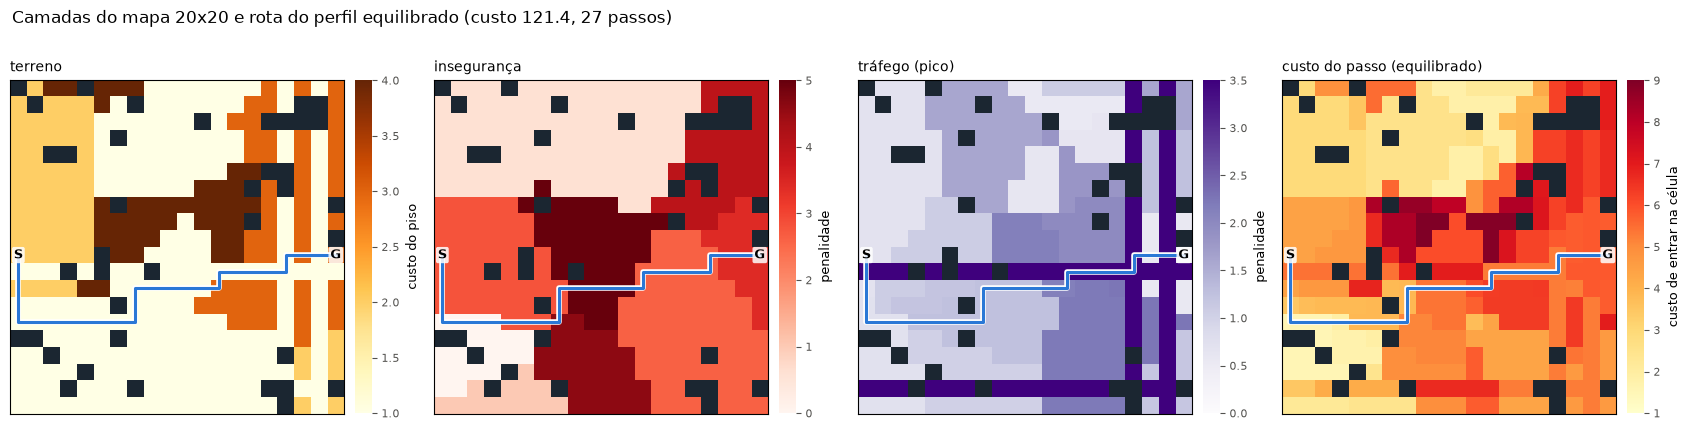

In [24]:
custo_eq = custo_do_perfil(cam, "equilibrado")
r_eq = rota(vitrine, custo_eq)

paineis = [
    ("terreno", cam.terreno, "YlOrBr", 1, 4, "custo do piso"),
    ("insegurança", cam.inseguranca, "Reds", 0, None, "penalidade"),
    ("tráfego (pico)", cam.trafego, "Purples", 0, None, "penalidade"),
    ("custo do passo (equilibrado)", custo_eq.grade, "YlOrRd", 1, None, "custo de entrar na célula"),
]
fig, axes = plt.subplots(1, 4, figsize=(17, 4.6))
for ax, (nome, grade, cmap, vmin, vmax, rotulo) in zip(axes, paineis):
    img = desenhar_camada(vitrine, grade, ax, [r_eq], cmap=cmap, vmin=vmin, vmax=vmax,
                          cores=("#2a78d6",), titulo=nome)
    barra_de_cores(img, ax, rotulo)
plt.suptitle(f"Camadas do mapa 20x20 e rota do perfil equilibrado (custo {r_eq.custo:.1f}, "
             f"{len(r_eq.acoes)} passos)", x=0.01, ha="left")
plt.tight_layout()
plt.savefig(FIGURAS / "custo_camadas.png", dpi=150, bbox_inches="tight")
plt.show()

As camadas formam manchas (bairros), e não ruído célula a célula. As avenidas aparecem como faixas de asfalto no terreno e de trânsito máximo no tráfego. A rota (em azul) foi desenhada por cima de todas as camadas, mas só o último painel mostra o custo que o A* de fato enxerga. Buracos aparecem em preto.

### 2. Perfis de peso no mesmo mapa

Mesmo mapa, mesmos S e G e mesmas camadas. Só mudam os pesos. Para cada perfil, a tabela mostra a rota ótima (Dijkstra) e os nós expandidos pelo A* com a heurística admissível Manhattan × cmin (seção 4). As colunas `Σ terreno`, `Σ insegurança` e `Σ tráfego` somam cada camada ao longo da rota e mostram o que cada rota "paga", independentemente dos pesos.

In [25]:
rotas_vitrine, linhas = {}, []
for perfil in PERFIS:
    custo = custo_do_perfil(cam, perfil)
    otimo = rota(vitrine, custo)
    r = rota(vitrine, custo, heuristicas_de_custo(custo)["manhattan × cmin"])
    assert math.isclose(r.custo, otimo.custo)
    rec, fim, _ = executar_no_ambiente(vitrine, otimo.acoes)
    assert fim and rec == 1.0
    rotas_vitrine[perfil] = otimo
    exp = exposicao(cam, otimo)
    linhas.append({"perfil": perfil, "custo": otimo.custo, "passos": len(otimo.acoes),
                   "expandidos (Dijkstra)": otimo.expandidos, "expandidos (manhattan × cmin)": r.expandidos,
                   "Σ terreno": exp["terreno"], "Σ insegurança": exp["inseguranca"],
                   "Σ tráfego": exp["trafego"]})

assert len({tuple(r.caminho) for r in rotas_vitrine.values()}) == 3, "os perfis deveriam divergir"
pd.DataFrame(linhas).set_index("perfil").round(1)

,custo,passos,expandidos (Dijkstra),expandidos (manhattan × cmin),Σ terreno,Σ insegurança,Σ tráfego
perfil,,,,,,,
mais rápido,82.4,25,359,343,33.0,82.4,49.4
mais seguro,151.8,29,346,337,62.0,50.2,41.6
equilibrado,121.4,27,360,360,34.0,75.4,49.4


Cada rota é a melhor **para o seu perfil**. A tabela abaixo avalia cada rota (linhas) com a função de custo de cada perfil (colunas). O menor valor de cada coluna fica na diagonal.

In [26]:
cruzada = pd.DataFrame({
    f"custo no perfil {p}": {
        f"rota {q}": sum(custo_do_perfil(cam, p)(a, b) for a, b in zip(r.caminho, r.caminho[1:]))
        for q, r in rotas_vitrine.items()}
    for p in PERFIS}).round(1)
for p, q in zip(PERFIS, PERFIS):
    assert cruzada[f"custo no perfil {p}"].idxmin() == f"rota {q}"
cruzada

,custo no perfil mais rápido,custo no perfil mais seguro,custo no perfil equilibrado
rota mais rápido,82.4,207.0,125.3
rota mais seguro,103.6,151.8,126.2
rota equilibrado,83.4,194.7,121.4


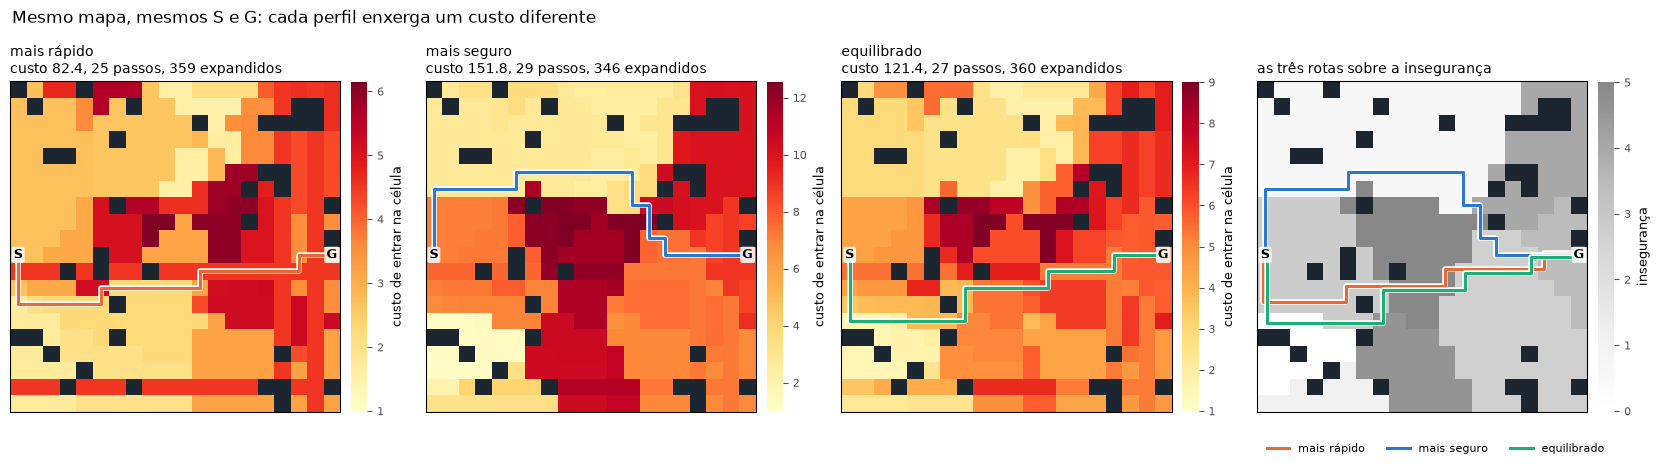

In [27]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4.6))
for ax, (perfil, r) in zip(axes, rotas_vitrine.items()):
    custo = custo_do_perfil(cam, perfil)
    img = desenhar_camada(vitrine, custo.grade, ax, [r], cmap="YlOrRd", vmin=1,
                          cores=(CORES_PERFIS[perfil],),
                          titulo=f"{perfil}\ncusto {r.custo:.1f}, {len(r.acoes)} passos, "
                                 f"{r.expandidos} expandidos")
    barra_de_cores(img, ax, "custo de entrar na célula")
cinza_claro = ListedColormap(plt.get_cmap("Greys")(np.linspace(0, 0.55, 256)))
img = desenhar_camada(vitrine, cam.inseguranca, axes[3], list(rotas_vitrine.values()), cmap=cinza_claro,
                      vmin=0,
                      cores=[CORES_PERFIS[p] for p in rotas_vitrine],
                      rotulos=list(rotas_vitrine), titulo="as três rotas sobre a insegurança")
barra_de_cores(img, axes[3], "insegurança")
axes[3].legend(frameon=False, fontsize=8, loc="lower left", bbox_to_anchor=(0, -0.16), ncol=3)
plt.suptitle("Mesmo mapa, mesmos S e G: cada perfil enxerga um custo diferente", x=0.01, ha="left")
plt.tight_layout()
plt.savefig(FIGURAS / "custo_perfis.png", dpi=150, bbox_inches="tight")
plt.show()

### 3. Perfis em vários mapas

Para não depender de um caso só, os três perfis rodam em mapas 16x16, 24x24 e 32x32 (15 sementes por tamanho, 90% de gelo, horário de pico), com S e G em duas disposições:

- **cantos opostos**: S em (0,0) e G em (n-1,n-1);
- **mesma linha**: S e G nas pontas da linha do meio.

Cada mapa é rodado com as seis heurísticas da seção 4. A coluna `rotas distintas` conta quantas rotas diferentes os três perfis produzem no mesmo mapa (de 1 a 3).

In [28]:
TAMANHOS_CUSTO = [16, 24, 32]
N_SEMENTES_CUSTO = 15
DISPOSICOES = {
    "cantos opostos": lambda n: ((0, 0), (n - 1, n - 1)),
    "mesma linha": lambda n: ((n // 2, 0), (n // 2, n - 1)),
}

def mapas_de_custo():
    for disposicao, pos in DISPOSICOES.items():
        for n in TAMANHOS_CUSTO:
            for k in range(N_SEMENTES_CUSTO):
                s, g = pos(n)
                mapa, _ = mapa_com_caminho(n, s, g, p_livre=0.9, semente=SEMENTE + k)
                yield disposicao, n, k, mapa

linhas = []
for disposicao, n, k, mapa in mapas_de_custo():
    cam_k = gerar_camadas(mapa, SEMENTE + k, horario="pico")
    s, g = encontrar(mapa, "S"), encontrar(mapa, "G")
    for perfil in PERFIS:
        custo = custo_do_perfil(cam_k, perfil)
        hs = heuristicas_de_custo(custo)
        for linha in rodar_custo(mapa, custo, hs):
            r = linha.pop("resultado")
            h = hs.get(linha["heuristica"], heuristica_nula)
            linhas.append({"disposição": disposicao, "tamanho": n, "mapa": k, "perfil": perfil,
                           **linha, "custo médio": custo.media, "h(S) / ótimo": h(s, g) / linha["otimo"],
                           "rota": tuple(r.caminho), **exposicao(cam_k, r)})

df_custo = pd.DataFrame(linhas)
df_otimo = df_custo[df_custo.heuristica == "nula (Dijkstra)"].copy()
df_otimo["rotas distintas"] = df_otimo.groupby(["disposição", "tamanho", "mapa"]).rota.transform("nunique")
print(f"{len(df_custo)} execuções em {df_otimo.groupby(['disposição', 'tamanho', 'mapa']).ngroups} mapas, "
      "todas validadas")

1620 execuções em 90 mapas, todas validadas


In [29]:
divergencia = (df_otimo.drop_duplicates(["disposição", "tamanho", "mapa"])
               .groupby(["disposição", "tamanho"])["rotas distintas"]
               .agg(**{"% com 3 rotas distintas": lambda s: 100 * (s == 3).mean(),
                       "% com pelo menos 2": lambda s: 100 * (s >= 2).mean()})
               .round(1))
divergencia

% com 3 rotas distintas  % com pelo menos 2
disposição     tamanho                                             
cantos opostos 16                          73.3               100.0
               24                          66.7               100.0
               32                         100.0               100.0
mesma linha    16                          13.3                53.3
               24                          80.0                93.3
               32                          80.0               100.0

In [30]:
cmin_exp = (df_custo[df_custo.heuristica == "manhattan × cmin"]
            .set_index(["disposição", "tamanho", "mapa", "perfil"]).expandidos)
tab_perfis = (df_otimo.join(cmin_exp.rename("expandidos (manhattan × cmin)"),
                            on=["disposição", "tamanho", "mapa", "perfil"])
              .groupby(["disposição", "perfil"], sort=False)
              [["custo", "passos", "expandidos", "expandidos (manhattan × cmin)",
                "terreno", "inseguranca", "trafego"]]
              .mean()
              .rename(columns={"expandidos": "expandidos (Dijkstra)", "terreno": "Σ terreno",
                               "inseguranca": "Σ insegurança", "trafego": "Σ tráfego"})
              .round(1))
tab_perfis

custo  passos  expandidos (Dijkstra)  \
disposição     perfil                                              
cantos opostos mais rápido  129.9    46.1                  554.7   
               mais seguro  177.0    46.3                  539.0   
               equilibrado  154.8    46.1                  553.8   
mesma linha    mais rápido   82.9    27.2                  480.9   
               mais seguro  122.1    29.9                  476.7   
               equilibrado  101.7    27.4                  481.7   

                            expandidos (manhattan × cmin)  Σ terreno  \
disposição     perfil                                                  
cantos opostos mais rápido                          528.5       62.9   
               mais seguro                          485.4       73.2   
               equilibrado                          516.3       63.8   
mesma linha    mais rápido                          273.4       41.4   
               mais seguro                          358.7       50.4   
               equilibrado                          313.0       41.5   

                            Σ insegurança  Σ tráfego  
disposição     perfil                                 
cantos opostos mais rápido           85.1       67.0  
               mais seguro           49.9       76.0  
               equilibrado           56.7       73.3  
mesma linha    mais rápido           49.5       41.6  
               mais seguro           35.8       48.4  
               equilibrado           42.3       43.8

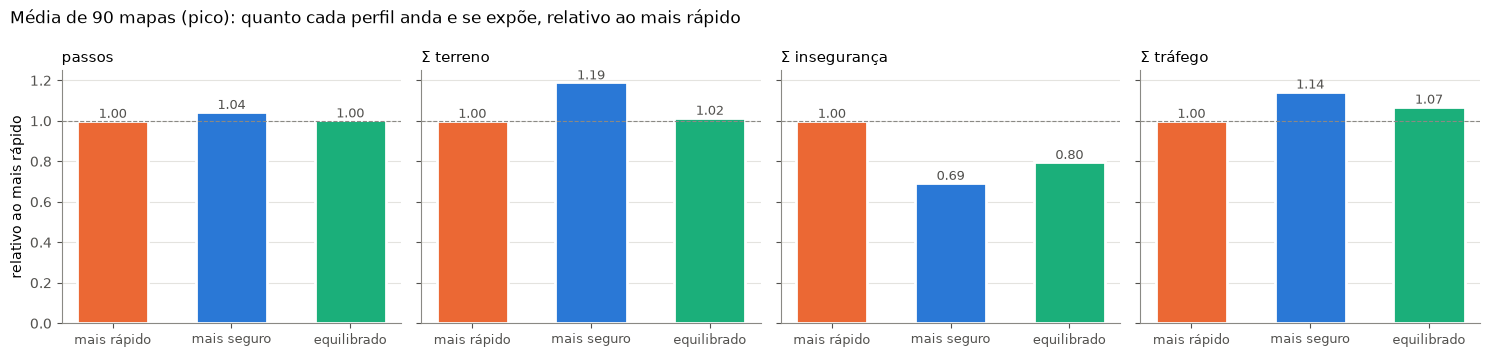

In [31]:
# Cada métrica relativa ao perfil "mais rápido" do mesmo mapa (1 = igual).
metricas_rel = {"passos": "passos", "terreno": "Σ terreno", "inseguranca": "Σ insegurança",
                "trafego": "Σ tráfego"}
base = df_otimo[df_otimo.perfil == "mais rápido"].set_index(["disposição", "tamanho", "mapa"])
rel = df_otimo.set_index(["disposição", "tamanho", "mapa"])
rel = pd.concat([rel[["perfil"]], rel[list(metricas_rel)] / base[list(metricas_rel)]], axis=1)
media_rel = rel.groupby("perfil", sort=False).mean()

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
for ax, (col, nome) in zip(axes, metricas_rel.items()):
    v = media_rel[col]
    ax.bar(range(len(v)), v, color=[CORES_PERFIS[p] for p in v.index], width=0.6,
           edgecolor="white", linewidth=2)
    for x, y in enumerate(v):
        ax.text(x, y, f"{y:.2f}", ha="center", va="bottom", fontsize=9, color="#52514e")
    ax.axhline(1, color="#8a8984", linewidth=0.8, linestyle="--")
    ax.set_xticks(range(len(v)), v.index, fontsize=9)
    estilo(ax, nome, "", "relativo ao mais rápido" if col == "passos" else "")
plt.suptitle(f"Média de {len(base)} mapas (pico): quanto cada perfil anda e se expõe, "
             "relativo ao mais rápido", x=0.01, ha="left")
plt.tight_layout()
plt.savefig(FIGURAS / "custo_perfis_mapas.png", dpi=150, bbox_inches="tight")
plt.show()

### 4. Heurísticas e admissibilidade

Com custo variável, a Manhattan pura continua admissível (todo passo custa pelo menos 1), mas fica fraca: ela estima 1 por passo enquanto o passo real custa bem mais. As heurísticas testadas, todas da forma $h = \text{fator} \times \text{Manhattan}$, são:

| Heurística | Fator | Admissível? |
|---|---|---|
| manhattan | 1 | sim |
| manhattan × cmin | menor custo de passo do mapa | sim: qualquer caminho tem pelo menos Manhattan passos, cada um custando pelo menos cmin |
| manhattan × média | custo médio das células livres | não garantido |
| manhattan × máx | maior custo de passo do mapa | não: só acerta se a rota inteira for pelo pior bairro |
| 2 × manhattan × cmin | 2·cmin | não garantido, mas o custo fica no máximo 2× o ótimo |

As colunas `cmin` e `custo médio` são o menor custo de passo e o custo médio das células livres de cada mapa. A coluna `h(S) / ótimo` mede o quanto a heurística acerta o custo real logo no início. Uma heurística admissível tem esse valor ≤ 1, e quanto mais perto de 1, menos nós a busca expande. `% subótimos` conta em quantos mapas o custo ficou acima do de Dijkstra.

In [32]:
df_custo["subotimo"] = df_custo["excesso_%"] > 1e-9
tab_hc = (df_custo.groupby(["perfil", "heuristica"], sort=False)
          .agg(cmin=("cmin", "mean"), **{"custo médio": ("custo médio", "mean")},
               **{"h(S) / ótimo": ("h(S) / ótimo", "mean"),
                  "h(S) / ótimo máx.": ("h(S) / ótimo", "max")},
               expandidos=("expandidos", "mean"),
               **{"% subótimos": ("subotimo", lambda s: 100 * s.mean()),
                  "excesso médio (%)": ("excesso_%", "mean"),
                  "excesso máx. (%)": ("excesso_%", "max")})
          .round(2))
tab_hc

cmin  custo médio  h(S) / ótimo  \
perfil      heuristica                                              
mais rápido nula (Dijkstra)       1.60         3.54          0.00   
            manhattan             1.60         3.54          0.32   
            manhattan × cmin      1.60         3.54          0.51   
            manhattan × média     1.60         3.54          1.13   
            manhattan × máx       1.60         3.54          1.91   
            2 × manhattan × cmin  1.60         3.54          1.02   
mais seguro nula (Dijkstra)       1.72         5.54          0.00   
            manhattan             1.72         5.54          0.23   
            manhattan × cmin      1.72         5.54          0.39   
            manhattan × média     1.72         5.54          1.26   
            manhattan × máx       1.72         5.54          2.59   
            2 × manhattan × cmin  1.72         5.54          0.78   
equilibrado nula (Dijkstra)       1.74         4.33          0.00   
            manhattan             1.74         4.33          0.26   
            manhattan × cmin      1.74         4.33          0.46   
            manhattan × média     1.74         4.33          1.14   
            manhattan × máx       1.74         4.33          2.07   
            2 × manhattan × cmin  1.74         4.33          0.92   

                                  h(S) / ótimo máx.  expandidos  % subótimos  \
perfil      heuristica                                                         
mais rápido nula (Dijkstra)                    0.00      517.81         0.00   
            manhattan                          0.46      461.68         0.00   
            manhattan × cmin                   0.72      400.93         0.00   
            manhattan × média                  1.47       82.98        74.44   
            manhattan × máx                    2.75       40.53        91.11   
            2 × manhattan × cmin               1.44      137.76        63.33   
mais seguro nula (Dijkstra)                    0.00      507.83         0.00   
            manhattan                          0.47      461.96         0.00   
            manhattan × cmin                   0.82      422.06         0.00   
            manhattan × média                  2.25      109.50        77.78   
            manhattan × máx                    4.84       40.22        93.33   
            2 × manhattan × cmin               1.65      309.77        25.56   
equilibrado nula (Dijkstra)                    0.00      517.74         0.00   
            manhattan                          0.39      472.22         0.00   
            manhattan × cmin                   0.80      414.67         0.00   
            manhattan × média                  1.76       76.53        75.56   
            manhattan × máx                    3.28       39.90        93.33   
            2 × manhattan × cmin               1.61      201.70        38.89   

                                  excesso médio (%)  excesso máx. (%)  
perfil      heuristica                                                 
mais rápido nula (Dijkstra)                    0.00              0.00  
            manhattan                          0.00              0.00  
            manhattan × cmin                   0.00              0.00  
            manhattan × média                  3.73             18.13  
            manhattan × máx                   13.25             58.05  
            2 × manhattan × cmin               2.10             13.66  
mais seguro nula (Dijkstra)                    0.00              0.00  
            manhattan                          0.00              0.00  
            manhattan × cmin                   0.00              0.00  
            manhattan × média                  4.96             28.20  
            manhattan × máx                   21.53             87.41  
            2 × manhattan × cmin               0.55             14.54  
equilibrado nula (Dijkstra)                 

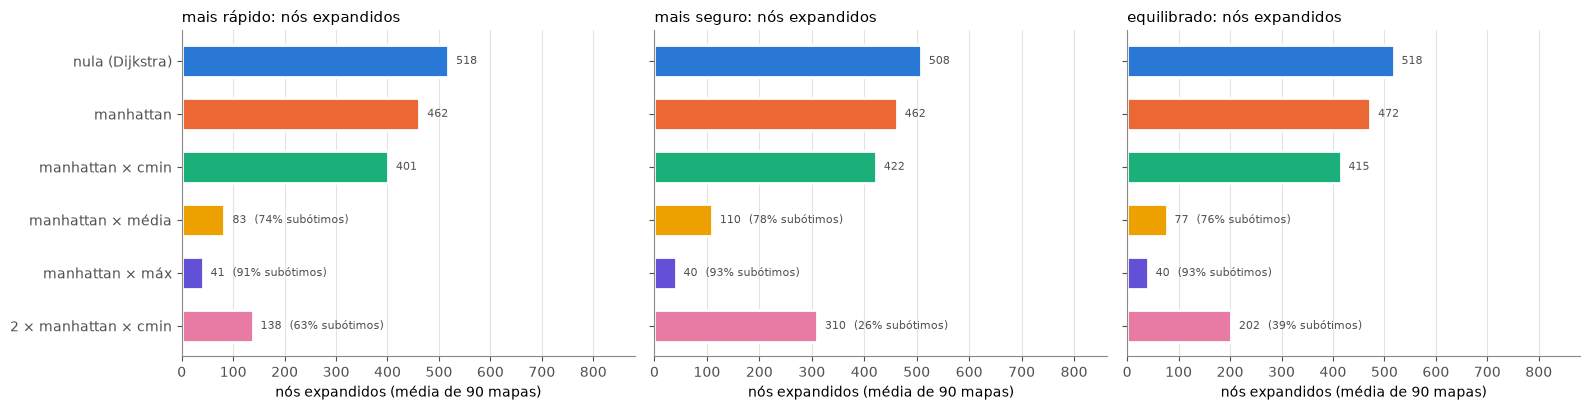

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, perfil in zip(axes, PERFIS):
    d = tab_hc.loc[perfil].reset_index()
    y = list(range(len(d)))
    ax.barh(y, d.expandidos, color=[CORES_CUSTO[n] for n in d.heuristica], height=0.6,
            edgecolor="white", linewidth=2)
    for yi, (v, sub) in enumerate(zip(d.expandidos, d["% subótimos"])):
        rotulo = f"{v:.0f}" + (f"  ({sub:.0f}% subótimos)" if sub > 0 else "")
        ax.text(v, yi, "  " + rotulo, va="center", fontsize=8, color="#52514e")
    ax.set_yticks(y, d.heuristica)
    estilo(ax, f"{perfil}: nós expandidos", "nós expandidos (média de 90 mapas)", "")
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", color="#e4e3df", linewidth=0.8)
    ax.set_xlim(0, d.expandidos.max() * 1.7)
axes[0].invert_yaxis()
plt.tight_layout()
plt.savefig(FIGURAS / "custo_heuristicas.png", dpi=150, bbox_inches="tight")
plt.show()

No mapa de vitrine, a quebra de admissibilidade aparece na própria rota. Com Manhattan × máx, o A* quase não se afasta da linha reta e aceita atravessar bairros caros.

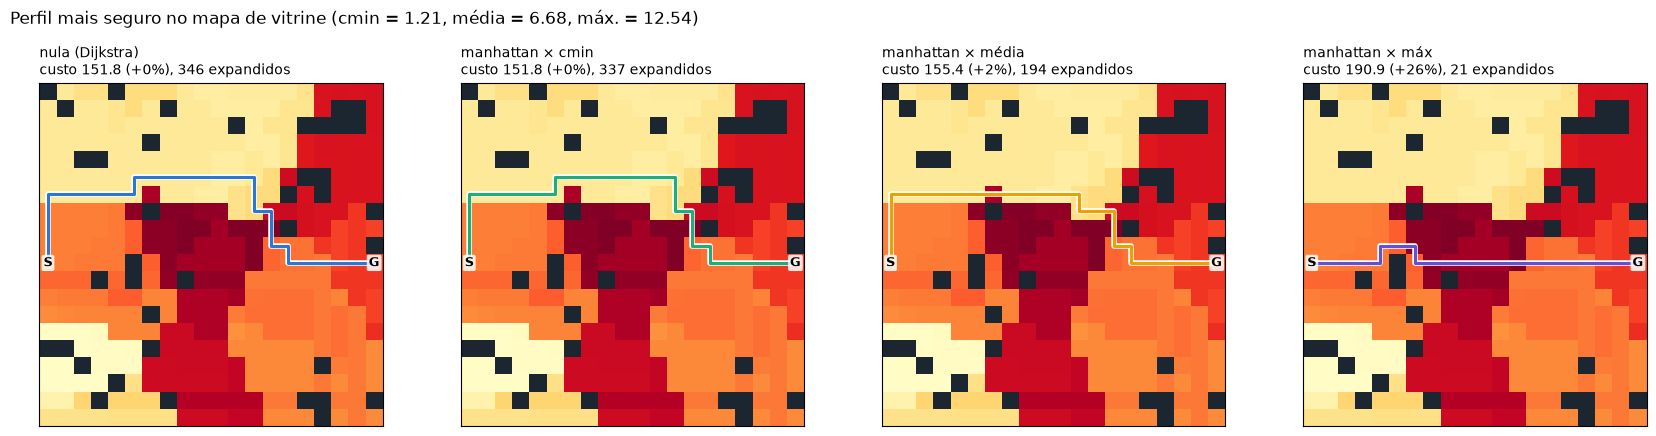

In [34]:
custo = custo_do_perfil(cam, "mais seguro")
hs = heuristicas_de_custo(custo)
casos_h = {"nula (Dijkstra)": heuristica_nula, "manhattan × cmin": hs["manhattan × cmin"],
           "manhattan × média": hs["manhattan × média"], "manhattan × máx": hs["manhattan × máx"]}
fig, axes = plt.subplots(1, 4, figsize=(17, 4.4))
for ax, (nome, h) in zip(axes, casos_h.items()):
    r = rota(vitrine, custo, h)
    rec, fim, _ = executar_no_ambiente(vitrine, r.acoes)
    assert fim and rec == 1.0
    excesso = 100 * (r.custo / rotas_vitrine["mais seguro"].custo - 1)
    desenhar_camada(vitrine, custo.grade, ax, [r], cmap="YlOrRd", vmin=1, cores=(CORES_CUSTO[nome],),
                    titulo=f"{nome}\ncusto {r.custo:.1f} (+{excesso:.0f}%), {r.expandidos} expandidos")
plt.suptitle(f"Perfil mais seguro no mapa de vitrine (cmin = {custo.minimo:.2f}, "
             f"média = {custo.media:.2f}, máx. = {custo.maximo:.2f})", x=0.01, ha="left")
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.savefig(FIGURAS / "custo_admissibilidade.png", dpi=150, bbox_inches="tight")
plt.show()

### 5. Horário: pico × madrugada

A cidade é a mesma (mesmos bairros, pisos, ocorrências e avenidas), e só muda a conversão da intensidade de trânsito em penalidade:

| Horário | Penalidade de tráfego |
|---|---|
| pico | 0,5 + 3 × intensidade |
| normal | 1,5 × intensidade |
| madrugada | 0,3 × intensidade |

As avenidas têm intensidade 1 e piso de asfalto. De madrugada são o caminho mais barato. No pico ficam congestionadas.

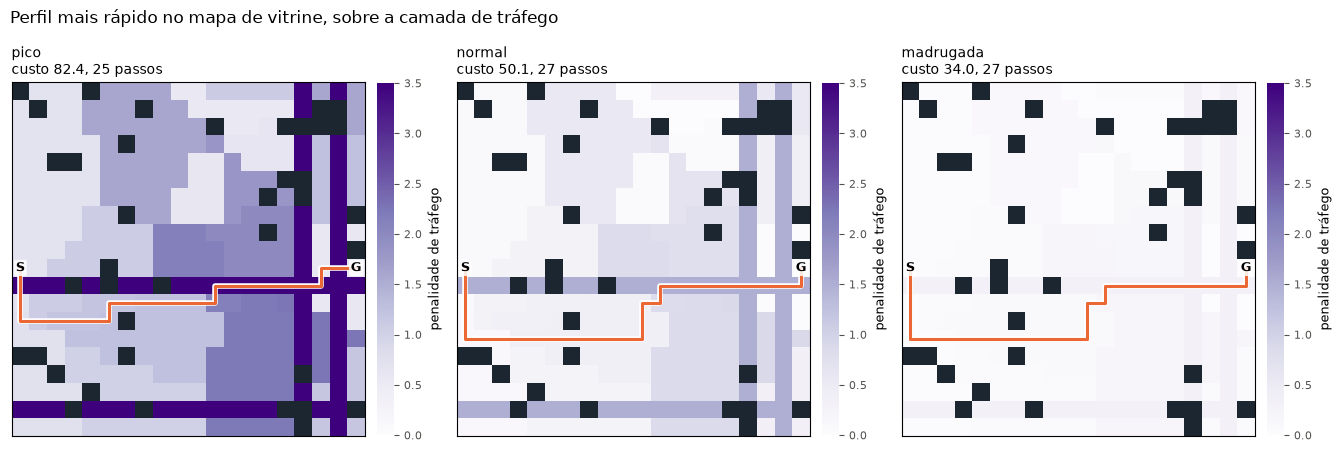

,custo,passos,células de avenida na rota,Σ tráfego,cmin
horário,,,,,
pico,82.42,25,9,49.42,1.52
normal,50.12,27,10,20.12,1.01
madrugada,34.02,27,10,4.02,1.00


In [35]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.6))
linhas, rotas_hor = [], {}
vmax = HORARIOS["pico"][0] + HORARIOS["pico"][1]
for ax, horario in zip(axes, HORARIOS):
    cam_h = gerar_camadas(vitrine, SEMENTE_VITRINE, horario=horario)
    custo = custo_do_perfil(cam_h, "mais rápido")
    r = rota(vitrine, custo)
    rotas_hor[horario] = r
    exp = exposicao(cam_h, r)
    linhas.append({"horário": horario, "custo": r.custo, "passos": len(r.acoes),
                   "células de avenida na rota": int(sum(cam_h.avenidas[c] for c in r.caminho[1:])),
                   "Σ tráfego": exp["trafego"], "cmin": custo.minimo})
    img = desenhar_camada(vitrine, cam_h.trafego, ax, [r], cmap="Purples", vmin=0, vmax=vmax,
                          cores=(CORES_PERFIS["mais rápido"],),
                          titulo=f"{horario}\ncusto {r.custo:.1f}, {len(r.acoes)} passos")
    barra_de_cores(img, ax, "penalidade de tráfego")
plt.suptitle("Perfil mais rápido no mapa de vitrine, sobre a camada de tráfego", x=0.01, ha="left")
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.savefig(FIGURAS / "custo_horario.png", dpi=150, bbox_inches="tight")
plt.show()
assert rotas_hor["pico"].caminho != rotas_hor["madrugada"].caminho
pd.DataFrame(linhas).set_index("horário").round(2)

Nos 90 mapas da seção 3, com os perfis mais rápido e equilibrado, a tabela mostra o custo, o uso de avenidas, a frequência com que a rota muda em relação à madrugada e o efeito do horário nas heurísticas.

In [36]:
linhas = []
for disposicao, n, k, mapa in mapas_de_custo():
    for perfil in ("mais rápido", "equilibrado"):
        rotas_k = {}
        for horario in HORARIOS:
            cam_h = gerar_camadas(mapa, SEMENTE + k, horario=horario)
            custo = custo_do_perfil(cam_h, perfil)
            hs = heuristicas_de_custo(custo)
            res = {l["heuristica"]: l for l in rodar_custo(mapa, custo, {
                "manhattan": hs["manhattan"], "manhattan × cmin": hs["manhattan × cmin"]})}
            r = res["nula (Dijkstra)"]["resultado"]
            rotas_k[horario] = r.caminho
            linhas.append({"perfil": perfil, "horário": horario, "custo": r.custo,
                           "passos": len(r.acoes),
                           "% da rota em avenida": 100 * np.mean([cam_h.avenidas[c] for c in r.caminho[1:]]),
                           "rota igual à da madrugada": None, "cmin": custo.minimo,
                           "expandidos (Dijkstra)": r.expandidos,
                           "expandidos (manhattan)": res["manhattan"]["expandidos"],
                           "expandidos (manhattan × cmin)": res["manhattan × cmin"]["expandidos"]})
        for linha, horario in zip(linhas[-len(HORARIOS):], HORARIOS):
            linha["rota igual à da madrugada"] = rotas_k[horario] == rotas_k["madrugada"]

df_hor = pd.DataFrame(linhas)
tab_hor = (df_hor.drop(columns="rota igual à da madrugada")
           .groupby(["perfil", "horário"], sort=False).mean(numeric_only=True))
tab_hor["% rotas iguais à da madrugada"] = 100 * df_hor.groupby(["perfil", "horário"], sort=False)[
    "rota igual à da madrugada"].mean()
tab_hor.round(1)

custo  passos  % da rota em avenida  cmin  \
perfil      horário                                                
mais rápido pico       106.4    36.7                   9.0   1.6   
            normal      69.2    37.2                  12.9   1.1   
            madrugada   51.0    37.3                  22.9   1.0   
equilibrado pico       128.2    36.7                  11.6   1.7   
            normal     100.4    37.0                  15.6   1.3   
            madrugada   86.6    37.4                  22.4   1.2   

                       expandidos (Dijkstra)  expandidos (manhattan)  \
perfil      horário                                                    
mais rápido pico                       517.8                   461.7   
            normal                     518.5                   400.8   
            madrugada                  518.1                   303.2   
equilibrado pico                       517.7                   472.2   
            normal                     517.6                   448.1   
            madrugada                  518.1                   426.8   

                       expandidos (manhattan × cmin)  \
perfil      horário                                    
mais rápido pico                               400.9   
            normal                             392.8   
            madrugada                          299.4   
equilibrado pico                               414.7   
            normal                             420.2   
            madrugada                          406.5   

                       % rotas iguais à da madrugada  
perfil      horário                                   
mais rápido pico                                22.2  
            normal                              43.3  
            madrugada                          100.0  
equilibrado pico                                26.7  
            normal                              46.7  
            madrugada                          100.0

### 6. Variável extra: chuva

Além das três variáveis sugeridas, criamos uma quarta: o **clima**. Com chuva, o custo do piso muda (o barro vira atoleiro e o pedregulho escorrega, enquanto a areia fica mais firme) e o trânsito aumenta 50%:

| Piso | Seco | Chuva |
|---|---|---|
| asfalto | 1 | 1 |
| pedregulho | 2 | 2,5 |
| barro | 3 | 6 |
| areia | 4 | 4 |

A chuva não é uma camada nova. Ela altera as camadas de terreno e tráfego, como no aplicativo, em que a chuva muda o tempo estimado das mesmas ruas.

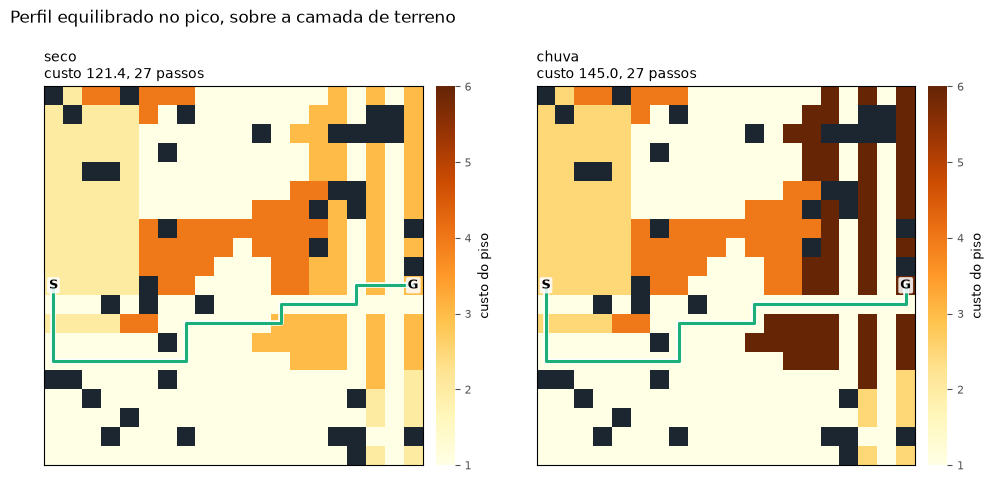

,custo,passos,células de asfalto,células de pedregulho,células de barro,células de areia
clima,,,,,,
seco,121.4,27,23,1,3,0
chuva,145.0,27,25,1,1,0


In [37]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.8))
linhas = []
for ax, clima in zip(axes, ("seco", "chuva")):
    cam_c = gerar_camadas(vitrine, SEMENTE_VITRINE, horario="pico", clima=clima)
    custo = custo_do_perfil(cam_c, "equilibrado")
    r = rota(vitrine, custo)
    rec, fim, _ = executar_no_ambiente(vitrine, r.acoes)
    assert fim and rec == 1.0
    tipos = [cam_c.tipo_terreno[c] for c in r.caminho[1:]]
    linhas.append({"clima": clima, "custo": r.custo, "passos": len(r.acoes),
                   **{f"células de {TERRENOS[t]}": tipos.count(t) for t in TERRENOS}})
    img = desenhar_camada(vitrine, cam_c.terreno, ax, [r], cmap="YlOrBr", vmin=1, vmax=6,
                          cores=(CORES_PERFIS["equilibrado"],),
                          titulo=f"{clima}\ncusto {r.custo:.1f}, {len(r.acoes)} passos")
    barra_de_cores(img, ax, "custo do piso")
plt.suptitle("Perfil equilibrado no pico, sobre a camada de terreno", x=0.01, ha="left")
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.savefig(FIGURAS / "custo_clima.png", dpi=150, bbox_inches="tight")
plt.show()
pd.DataFrame(linhas).set_index("clima").round(1)

In [38]:
linhas = []
for disposicao, n, k, mapa in mapas_de_custo():
    for perfil in PERFIS:
        res = {}
        for clima in ("seco", "chuva"):
            cam_c = gerar_camadas(mapa, SEMENTE + k, horario="pico", clima=clima)
            custo = custo_do_perfil(cam_c, perfil)
            r = rodar_custo(mapa, custo, {"manhattan × cmin": heuristicas_de_custo(custo)["manhattan × cmin"]})[0]["resultado"]
            res[clima] = (r, [cam_c.tipo_terreno[c] for c in r.caminho[1:]])
        (r_s, t_s), (r_c, t_c) = res["seco"], res["chuva"]
        linhas.append({"perfil": perfil, "custo seco": r_s.custo, "custo chuva": r_c.custo,
                       "passos seco": len(r_s.acoes), "passos chuva": len(r_c.acoes),
                       "barro seco": t_s.count(3), "barro chuva": t_c.count(3),
                       "rota muda": r_s.caminho != r_c.caminho})

df_clima = pd.DataFrame(linhas)
tab_clima = df_clima.drop(columns="rota muda").groupby("perfil", sort=False).mean(numeric_only=True)
tab_clima["aumento do custo (%)"] = 100 * (tab_clima["custo chuva"] / tab_clima["custo seco"] - 1)
tab_clima["% rotas que mudam"] = 100 * df_clima.groupby("perfil", sort=False)["rota muda"].mean()
tab_clima.round(1)

,custo seco,custo chuva,passos seco,passos chuva,barro seco,barro chuva,aumento do custo (%),% rotas que mudam
perfil,,,,,,,,
mais rápido,106.4,143.7,36.7,37.1,2.9,1.6,35.0,45.6
mais seguro,149.6,163.7,38.1,38.1,4.9,3.6,9.4,50.0
equilibrado,128.2,159.2,36.7,37.0,3.1,1.9,24.1,52.2


### Discussão dos experimentos de custo

**Cada perfil escolhe outra rota.** No mapa de vitrine, com o mesmo mapa e os mesmos S e G, os três perfis fazem três rotas diferentes. A rota mais rápida tem 25 passos e custo 82,4. A mais segura dá a volta por cima do bairro perigoso: anda 29 passos e quase dobra a soma de terreno (33 → 62), mas reduz a insegurança acumulada de 82 para 50. A equilibrada fica no meio, com 27 passos. A tabela cruzada confirma que cada rota é a mais barata só no próprio perfil. A rota mais segura, por exemplo, custaria 103,6 no perfil mais rápido, contra 82,4 da rota dele. Não existe uma "melhor rota" sem dizer antes o que se quer minimizar, e isso é exatamente o que os pesos fazem.

Nos 90 mapas, os perfis divergem na maioria dos casos. Com S e G em cantos opostos, pelo menos dois perfis escolhem rotas diferentes em 100% dos mapas, e os três escolhem rotas distintas em 67% a 100%. Com S e G na mesma linha, no 16x16 os três só divergem em 13% dos mapas: o mapa é pequeno, os buracos fecham as alternativas e sobra pouco espaço para desviar sem andar muito. Em média, comparado ao mais rápido:

- o **mais seguro** reduz a insegurança acumulada em 31%, com 4% de passos a mais, 19% a mais de terreno e 14% a mais de trânsito;
- o **equilibrado** reduz a insegurança em 20%, com o mesmo número de passos e quase o mesmo terreno (+2%).

O equilibrado é um bom acordo: perde pouco em tempo e ganha bastante em segurança.

**Efeito de cada variável.**
- *Terreno*: é a camada mais "barata" de contornar, porque 45% dos bairros são de asfalto e as avenidas também (no mapa de vitrine, 58% das células livres são de asfalto). Ela pesa sobretudo quando um bairro de barro ou areia fica no caminho direto.
- *Insegurança*: é a variável que mais muda as rotas, porque a penalidade chega a 5 por célula e se concentra em poucos bairros (a média de ocorrências é sorteada com uma distribuição de cauda longa). Com peso 2, só a insegurança soma até 10 a cada passo num bairro perigoso, e um desvio de 4 passos já compensa.
- *Tráfego e horário*: a cidade é a mesma, mas a rota do perfil mais rápido no pico é diferente da rota da madrugada em 78% dos mapas. As avenidas ocupam 23% da rota de madrugada e só 9% no pico, quando estão congestionadas. No mapa de vitrine, a rota muda (25 passos no pico, 27 de madrugada), mas o número de células de avenida é parecido (9 e 10): a diferença no uso de avenidas aparece na média dos 90 mapas, não nesse caso.
- *Chuva (variável extra)*: aumenta o custo em 35% para o perfil mais rápido, mas só 9% para o mais seguro, que dá pouco peso ao terreno ($w_t = 0{,}3$). A rota muda em cerca de metade dos mapas, e o número de células de barro na rota cai quase pela metade (2,9 → 1,6 no mais rápido), quase sem passos a mais. A rota troca o barro por asfalto do lado.

**Heurísticas e admissibilidade.** O A* com Manhattan e com Manhattan × cmin achou exatamente o custo de Dijkstra nas 540 execuções admissíveis da seção 3 (de 1620) e em todas as execuções de horário e clima (o `rodar_custo` faz essa verificação). O preço da admissibilidade, porém, ficou alto:

- a **Manhattan pura** estima entre 23% e 32% do custo real a partir do S e só economiza cerca de 10% dos nós em relação a Dijkstra (≈ 465 contra ≈ 515). No experimento de cenário, com custo 1, a mesma Manhattan cortava até 89% dos nós;
- a **Manhattan × cmin** é a melhor admissível daqui, mas a economia continua pequena (≈ 20%, com 401 a 422 nós). O motivo é que o cmin (1,6 a 1,7) fica muito abaixo do custo médio de um passo (3,5 no mais rápido, 4,3 no equilibrado e 5,5 no mais seguro). A heurística precisa supor que o resto do caminho será todo pelo bairro mais barato do mapa. Esse valor depende muito do horário: de madrugada o cmin cai para 1,0 no perfil mais rápido, e aí Manhattan × cmin vira a Manhattan pura.

As heurísticas que superestimam mostram o outro lado:

- **Manhattan × média**: a estimativa inicial passa do custo real em média (`h(S) / ótimo` de 1,13 a 1,26). O A* expande 5 a 6 vezes menos nós, mas devolve rota subótima em 74% a 78% dos mapas, com excesso médio de 4% a 5% e máximo de 36%;
- **Manhattan × máx**: quase vira uma busca gulosa (cerca de 40 nós, praticamente só o caminho). É subótima em 91% a 93% dos mapas, com excesso de até 87%. No mapa de vitrine, ela atravessa o bairro perigoso em linha reta e paga 26% a mais;
- **2 × Manhattan × cmin**: tem uma garantia de qualidade, porque o custo nunca passa de 2× o ótimo (o `teste_custos` confere isso). Na prática, o excesso máximo foi de 20%. No perfil mais seguro, só 26% dos mapas ficam subótimos, porque nele o cmin é pequeno perto dos custos reais e $2 \cdot$cmin ainda subestima na maior parte do mapa.

A admissibilidade não quebra de uma vez: ela quebra quando o fator passa do custo real do resto do caminho, e isso depende do mapa. Por isso a Manhattan × média é subótima em ¾ dos mapas, e não em todos. O trade-off é o mesmo da Manhattan ponderada dos experimentos de cenário, só que aqui é mais forte: com custos heterogêneos, a distância entre a melhor heurística admissível e o custo real cresce, e a tentação de superestimar aumenta.

**Limitações.**
- As camadas são sintéticas, e os pesos e as conversões (5 ocorrências = 1 ponto de penalidade, base e escala do trânsito) foram escolhidos por nós, sem calibração com dados reais. Os resultados mostram tendências, não valores do mundo real.
- A soma ponderada esconde a fronteira de Pareto: cada perfil é só um ponto dela. Um aplicativo de verdade mostraria várias rotas e deixaria o usuário escolher.
- O trânsito é fixo durante a viagem. Num modelo mais realista, o custo dependeria do horário de chegada a cada célula, e o estado do A* teria de incluir o tempo.
- **Custo de curva** ficou de fora porque a `custo_fn(origem, destino)` não sabe de onde o agente veio. Para modelar isso, o estado precisaria ser (célula, direção), o que muda o espaço de busca do A*.
- O custo está só na célula de destino. Ir e voltar entre duas células pode custar valores diferentes, o que é razoável (entrar num bairro perigoso custa caro, sair dele não), mas é uma escolha do modelo.
- Heurísticas melhores e ainda admissíveis exigiriam pré-processamento, por exemplo distâncias exatas até alguns pontos de referência (landmarks/ALT) ou um Dijkstra reverso a partir do G. Isso fica fora do que foi visto na aula.
- O Gymnasium só confirma que a rota chega ao G sem cair em buraco. Ele não conhece os custos, então a otimalidade é conferida apenas pela comparação com Dijkstra.